# Whisking, wheel movement and engagement in the first training session

**Hypothesis.** LD1 (the main axis of individuality in proficient behaviour) loads heavily on
whisking, and LD1 tracks learning speed. If whisking early in training is an expression of
*engagement*, the mice that whisk more in their first session might be the ones that learn
fastest — and whisking should then also travel with the other engagement read-out we have,
moving the wheel.

**What this notebook does**

1. **Snippets** — first-session data where whisking (HMM state) and wheel speed sit on the same
   time-warped trial grid, so they can be seen and correlated bin by bin.
2. **Coupling** — how strongly whisking and wheel movement co-vary *within* a session, and
   whether that coupling also holds *between* mice.
3. **Whisking vs LD1** — first-session whisking probability against the mouse's mean LD1
   (with proficient whisking as the positive control, and first-session vs proficient whisking).
4. **Whisking vs learning speed** — first-session (and last-training) whisking against
   training time.

**Data**
- Whisk HMM state: legacy left-paw+wheel syllable files (`paw_wheel_session_1_…_04-09-2026`,
  `paw_wheel_last_training_…_04-09-2026`), 10 bins per trial phase; whisk = `(code // 8) % 2`.
- Wheel: raw training design matrices (`avg_wheel_vel`, ~30 Hz), cut into the same four phases
  and warped to the same 10 bins per phase in `whisk_wheel_data.py`.
- LD1: `mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026` via `lab_controls.py` (Alyx labs).
- Learning speed: `training_time_05-05-2026` (`training_days` = sessions before proficiency;
  log-transformed as in `lab_controls.py`). **Higher = slower.**

**Caveat that frames every across-mouse result here:** Early and Late have *one* session per mouse,
so every between-mouse correlation is attenuated by single-session reliability (see
`early_proficient_shared_subspace.ipynb`, `vigor/wheel/wheel_vigor_first_vs_proficient.ipynb`).
With n ≈ 45, only |r| ≳ 0.41 is detectable at 80% power.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, wilcoxon, t as t_dist
from statsmodels.stats.multitest import multipletests

HERE = pathlib.Path.cwd()
PI = HERE.parent
for p in (PI, HERE):
    sys.path.insert(0, str(p))

import paper_style as ps
ps.use('paper')
_argv, sys.argv = sys.argv, ['lab_controls']     # lab_controls parses argv at import
import lab_controls as lc
sys.argv = _argv
import whisk_wheel_data as wd

warnings.filterwarnings('ignore', category=RuntimeWarning)
WHISK_C, WHEEL_C = '#4C72B0', '#C44E52'
EP = wd.PHASES
NB = wd.N_PER_PHASE * len(EP)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## 1. Build the aligned first-session data

`label agreement` checks the alignment: for every trial, the correct/incorrect label carried in
the syllable file must match `feedbackType` at the trial table row the wheel was cut from.

In [2]:
trials, W, V, agree = wd.build('Early')
assert agree.min() == 1.0, 'syllable trials and trial-table rows disagree'

# Late (last training session): whisking only -- these sessions are past the end of the
# training trial tables / design matrices on this machine, so there is no wheel for them.
late_trials, W_late = wd.load_whisk('Late')
late_trials['whisk_frac'] = np.nanmean(W_late, axis=1)
print(f"Late: {len(late_trials)} trials, {late_trials.session.nunique()} sessions (whisk only)")

print(f"\nEarly whisking occupancy: {np.nanmean(W):.2f} of bins;  "
      f"wheel |v| when whisking {np.nanmean(V[W == 1]):.3f} vs not {np.nanmean(V[W == 0]):.3f}")

Early: 14563 trials, 47 sessions (47 with wheel); label agreement min 1.000, median 1.000


Late: 39878 trials, 55 sessions (whisk only)

Early whisking occupancy: 0.64 of bins;  wheel |v| when whisking 0.363 vs not 0.085


## 2. Snippets: whisking and wheel movement, trial by trial

Each panel strings together consecutive first-session trials on the warped grid
(4 phases × 10 bins per trial). Grey bands = whisk HMM state on; red line = |wheel velocity|.
Three mice spanning the range of LD1.

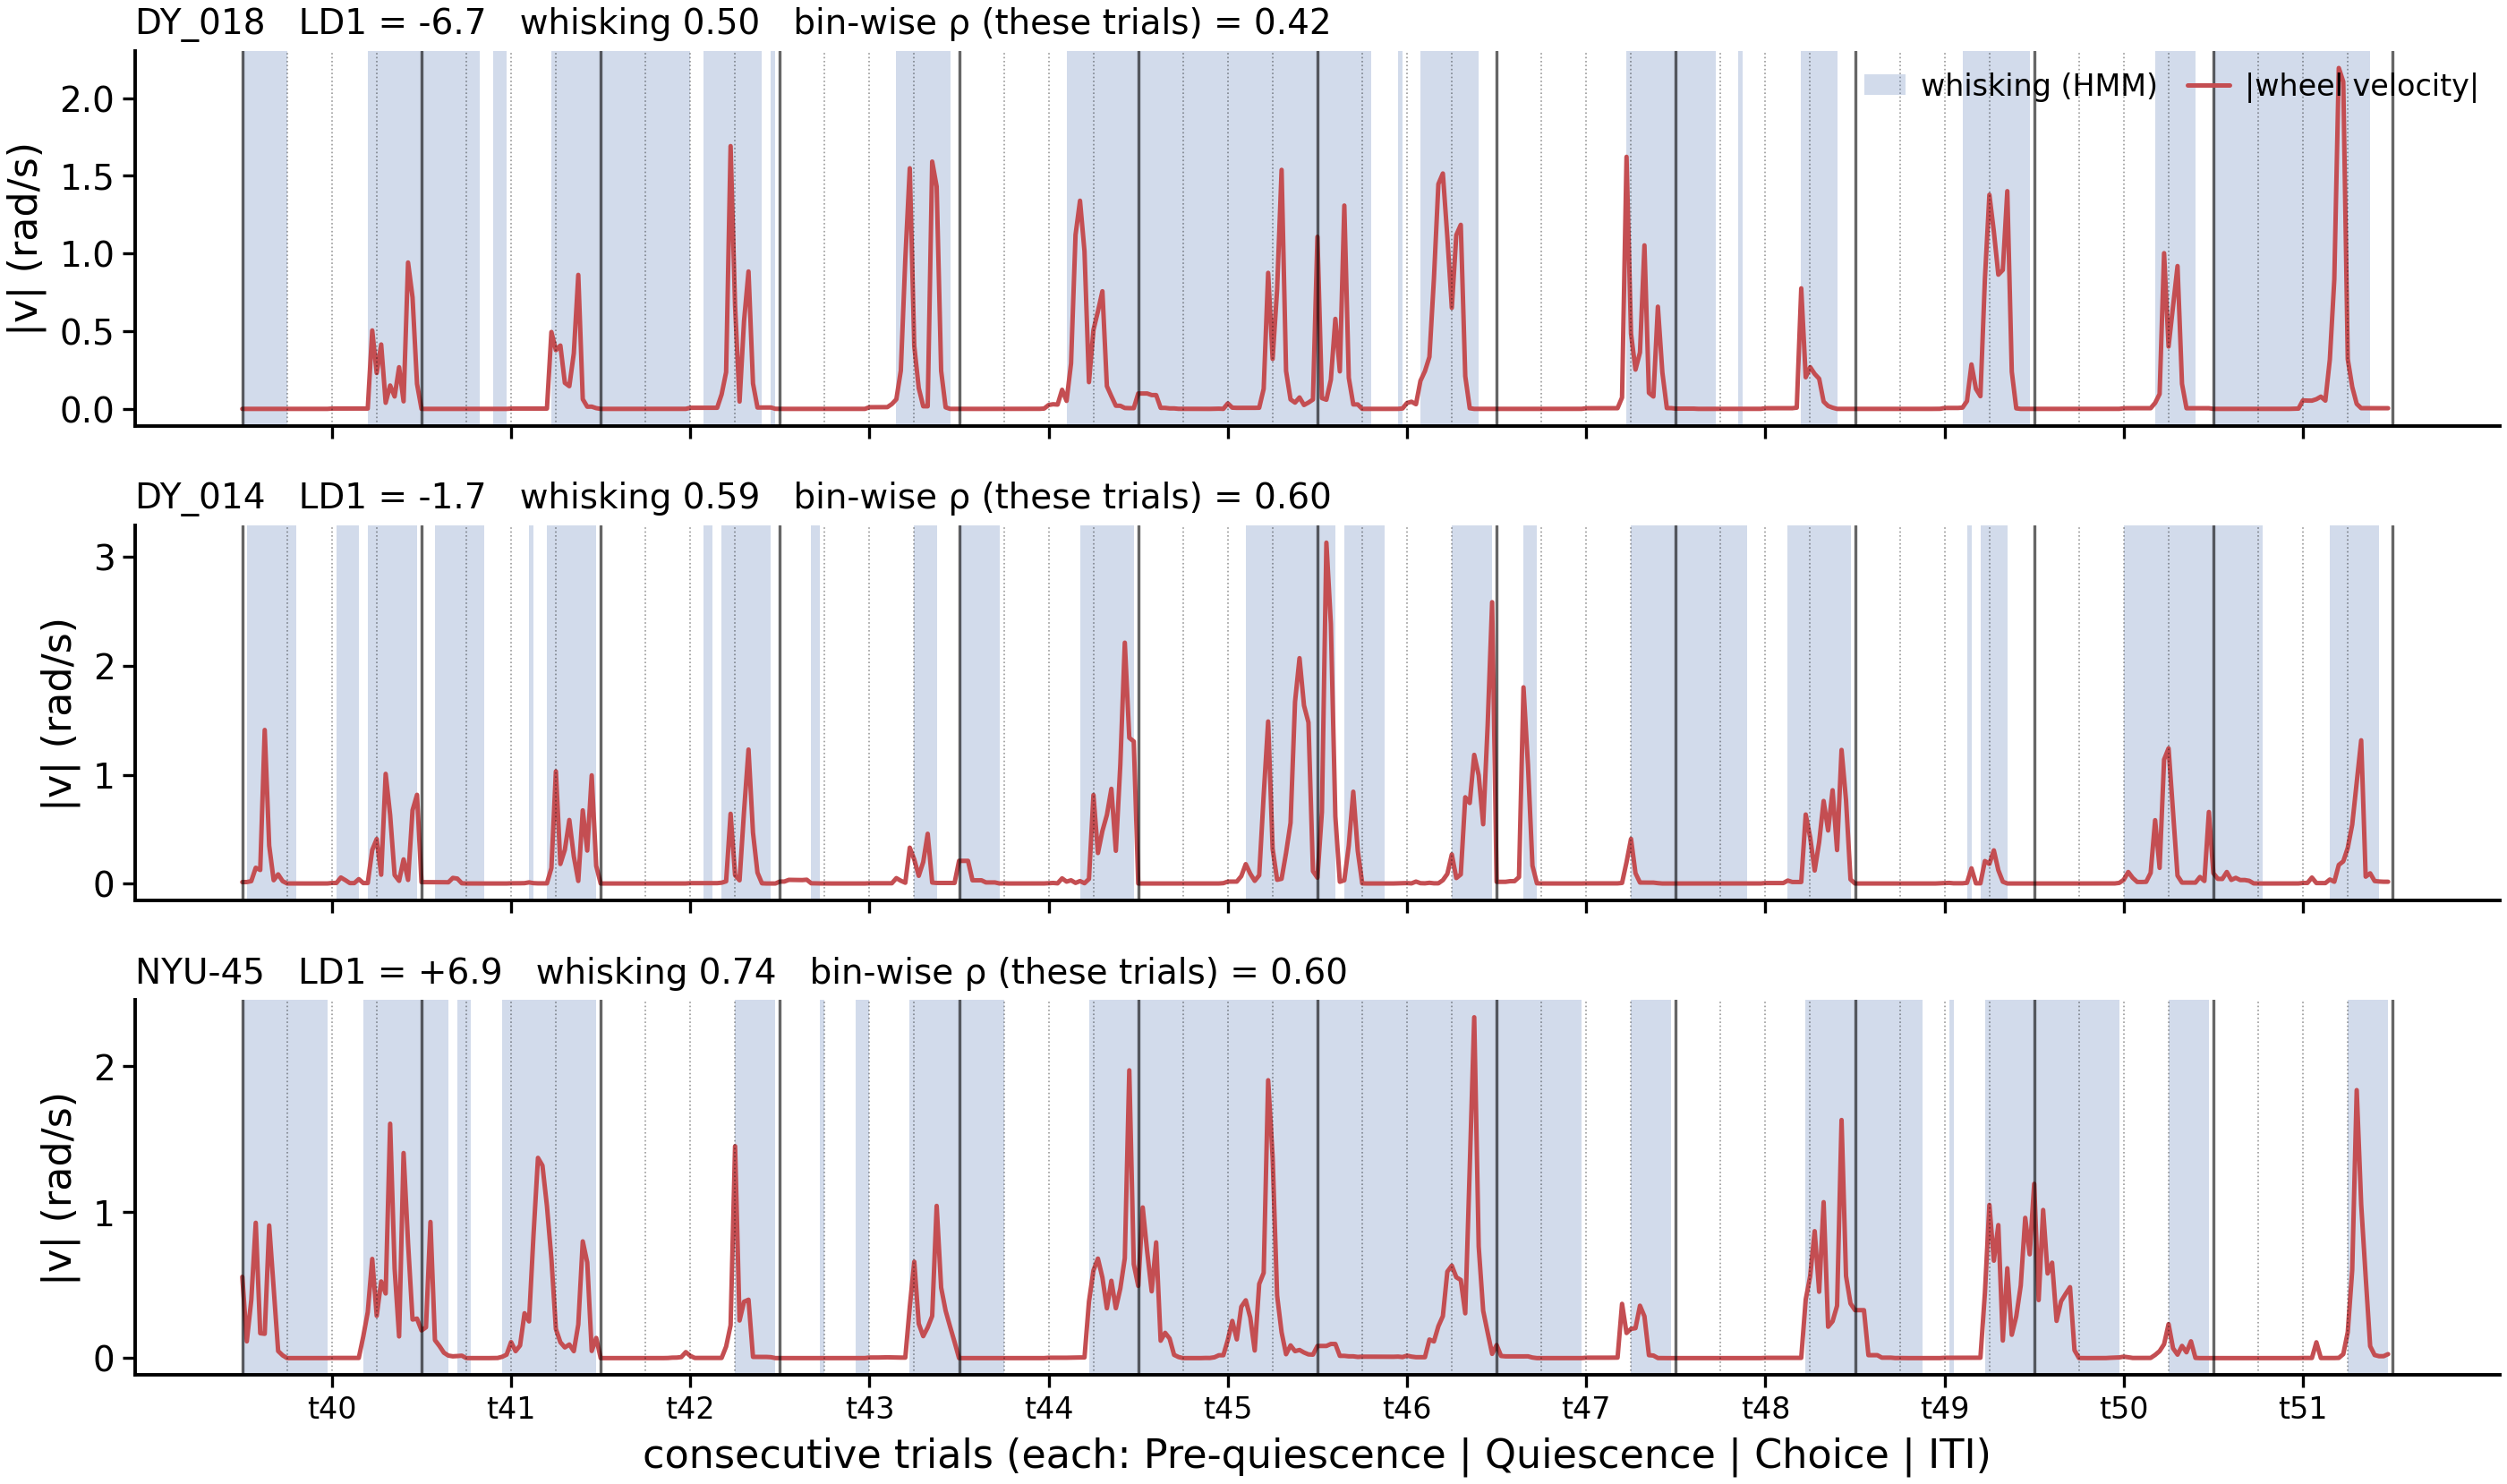

In [3]:
mouse_ld1 = lc.LDA.groupby('mouse_name')['LD1'].mean()
have = mouse_ld1.reindex(trials.mouse_name.unique()).dropna().sort_values()
examples = [have.index[2], have.index[len(have) // 2], have.index[-3]]
N_SHOW, START = 12, 40          # trials shown, first trial shown (skip the first minutes)

fig, axs = plt.subplots(len(examples), 1, figsize=(7.2, 1.45 * len(examples)), sharex=True)
for ax, m in zip(axs, examples):
    idx = np.flatnonzero(trials.mouse_name.to_numpy() == m)[START:START + N_SHOW]
    w = W[idx].ravel(); v = V[idx].ravel(); x = np.arange(len(w))
    ax.fill_between(x, 0, 1, where=w == 1, step='mid', color=WHISK_C, alpha=0.25, lw=0,
                    transform=ax.get_xaxis_transform(), label='whisking (HMM)')
    ax.plot(x, v, color=WHEEL_C, lw=0.9, label='|wheel velocity|')
    for t in range(N_SHOW + 1):
        ax.axvline(t * NB, color='k', lw=0.6, alpha=0.6)
    for t in range(N_SHOW):
        for k in (1, 2, 3):
            ax.axvline(t * NB + k * wd.N_PER_PHASE, color='k', lw=0.3, ls=':', alpha=0.4)
    r = spearmanr(W[idx].ravel(), V[idx].ravel(), nan_policy='omit')[0]
    ax.set_title(f'{m}   LD1 = {mouse_ld1[m]:+.1f}   whisking {np.nanmean(W[trials.mouse_name == m]):.2f}'
                 f'   bin-wise ρ (these trials) = {r:.2f}', fontsize=7, loc='left')
    ax.set_ylabel('|v| (rad/s)')
axs[0].legend(loc='upper right', fontsize=6, frameon=False, ncol=2)
axs[-1].set_xticks(np.arange(N_SHOW) * NB + NB / 2)
axs[-1].set_xticklabels([f't{START + i}' for i in range(N_SHOW)], fontsize=6)
axs[-1].set_xlabel('consecutive trials (each: Pre-quiescence | Quiescence | Choice | ITI)')
plt.tight_layout(); plt.show()

### Whole-session rasters for the same mice

Rows = trials in session order, columns = the 40 warped bins. Whisking (left) and wheel speed
(right) for the same trials.

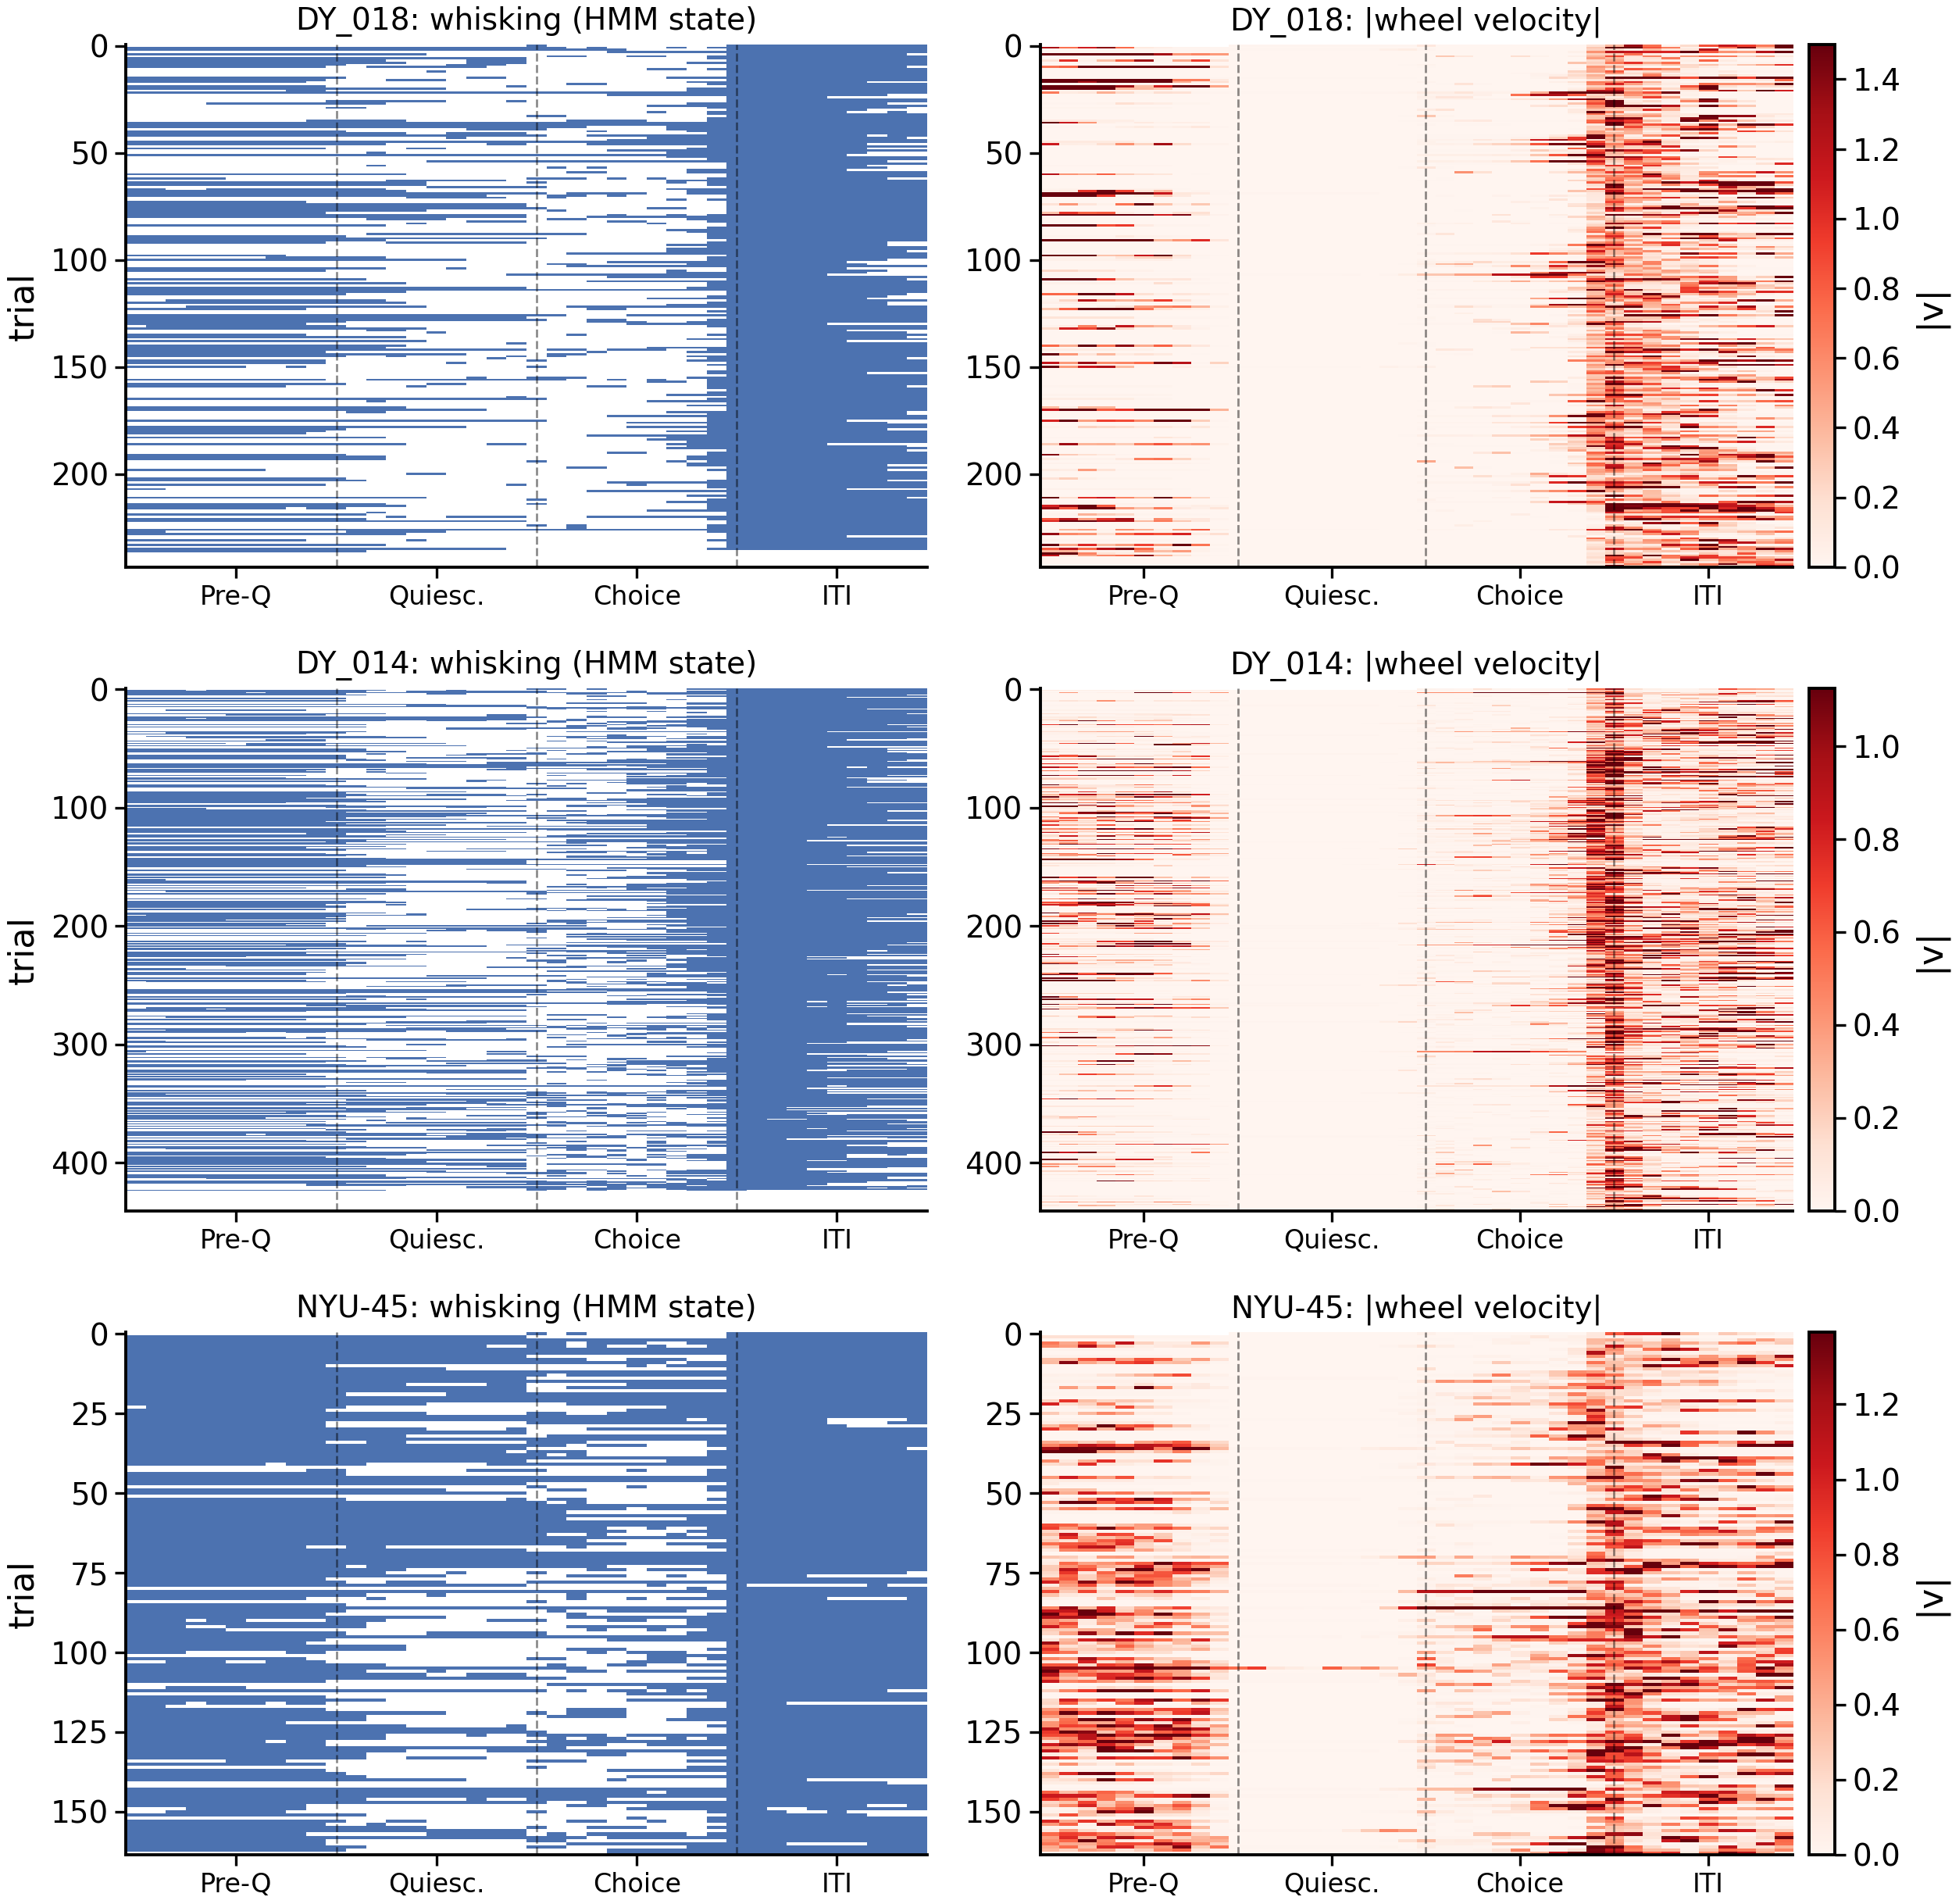

In [4]:
fig, axs = plt.subplots(len(examples), 2, figsize=(6.5, 2.1 * len(examples)))
for row, m in zip(axs, examples):
    idx = np.flatnonzero(trials.mouse_name.to_numpy() == m)
    row[0].imshow(W[idx], aspect='auto', cmap=ps._binary_cmap(WHISK_C), interpolation='nearest')
    vmax = np.nanpercentile(V[idx], 97)
    im = row[1].imshow(V[idx], aspect='auto', cmap='Reds', vmin=0, vmax=vmax, interpolation='nearest')
    plt.colorbar(im, ax=row[1], fraction=0.04, pad=0.02, label='|v|')
    for ax, ttl in zip(row, ['whisking (HMM state)', '|wheel velocity|']):
        ps.epoch_lines(ax, NB)
        ax.set_title(f'{m}: {ttl}', fontsize=7)
        ax.set_xticks([5, 15, 25, 35]); ax.set_xticklabels(ps.EPOCH_SHORT, fontsize=6)
    row[0].set_ylabel('trial')
plt.tight_layout(); plt.show()

### Average within-trial profile (all first sessions)

Mean over trials within each mouse, then mean ± s.e.m. over mice.

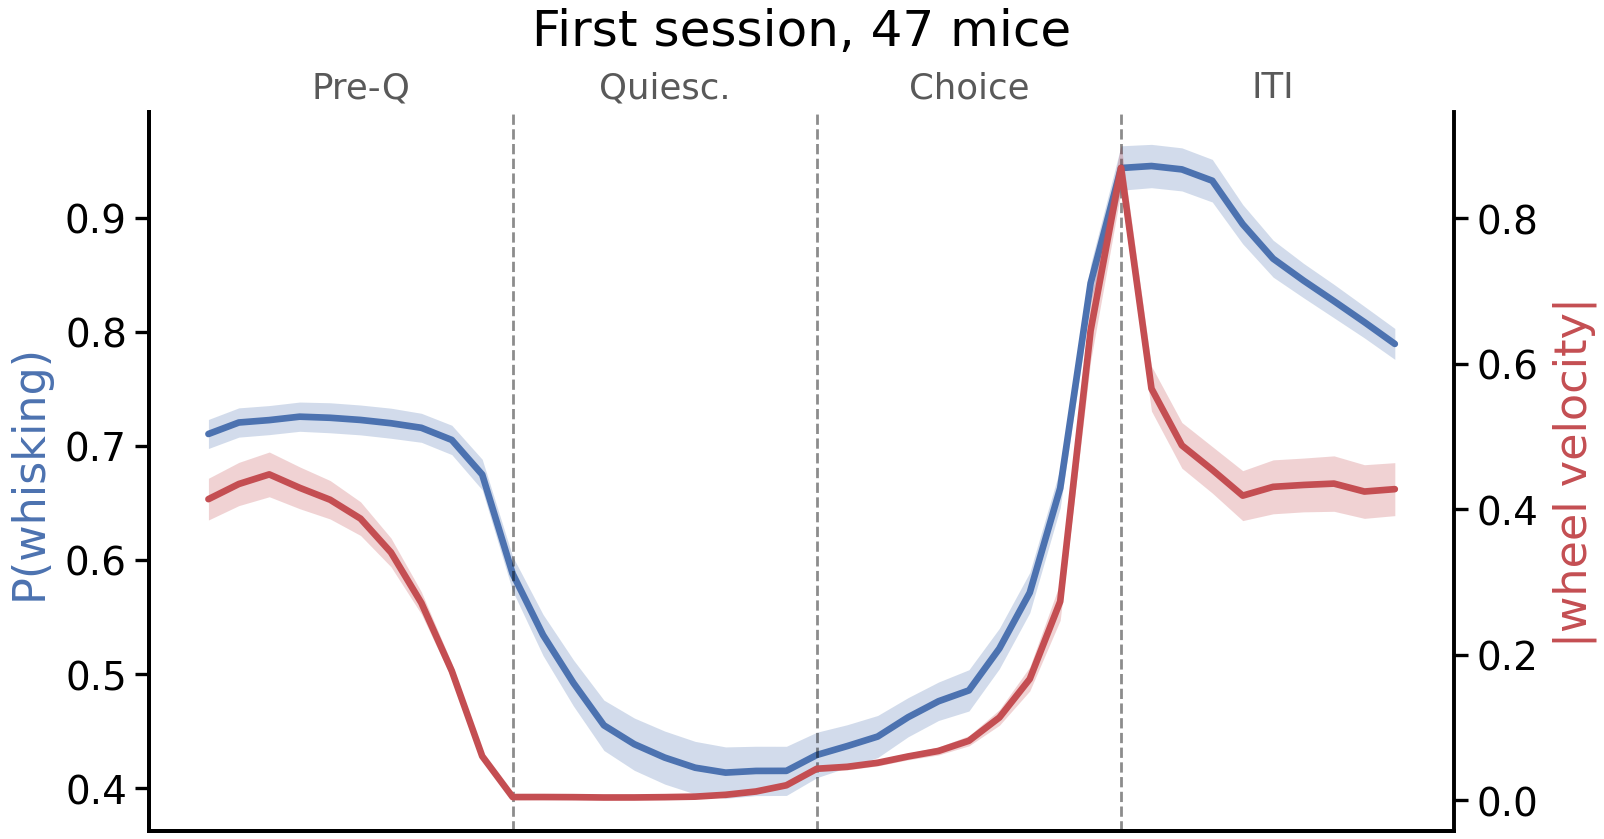

In [5]:
mice = trials.mouse_name.unique()
prof_w = np.vstack([np.nanmean(W[trials.mouse_name == m], 0) for m in mice])
prof_v = np.vstack([np.nanmean(V[trials.mouse_name == m], 0) for m in mice])

fig, ax = plt.subplots(figsize=(4.2, 2.3))
x = np.arange(NB)
for P, c, lbl, a in [(prof_w, WHISK_C, 'P(whisking)', ax)]:
    m_, s_ = P.mean(0), P.std(0) / np.sqrt(len(P))
    a.plot(x, m_, color=c); a.fill_between(x, m_ - s_, m_ + s_, color=c, alpha=0.25, lw=0)
ax.set_ylabel('P(whisking)', color=WHISK_C)
ax2 = ax.twinx()
m_, s_ = prof_v.mean(0), prof_v.std(0) / np.sqrt(len(prof_v))
ax2.plot(x, m_, color=WHEEL_C); ax2.fill_between(x, m_ - s_, m_ + s_, color=WHEEL_C, alpha=0.25, lw=0)
ax2.set_ylabel('|wheel velocity|', color=WHEEL_C); ax2.spines['right'].set_visible(True)
ps.epoch_lines(ax, NB, label=True, names=ps.EPOCH_SHORT)
ax.set_xticks([]); ax.set_title(f'First session, {len(mice)} mice', pad=12)
plt.tight_layout(); plt.show()

## 3. How tightly are whisking and wheel movement coupled?

Two levels, which need not agree:

* **Within session** — across the trials of one mouse, at a *fixed* warped bin, is the wheel
  moving faster on trials where the mouse is whisking? Fixing the bin removes the shared
  within-trial time course (both peak in the same phases), which would otherwise inflate any
  pooled correlation.
* **Between mice** — do the mice that whisk more in session 1 also move the wheel more?

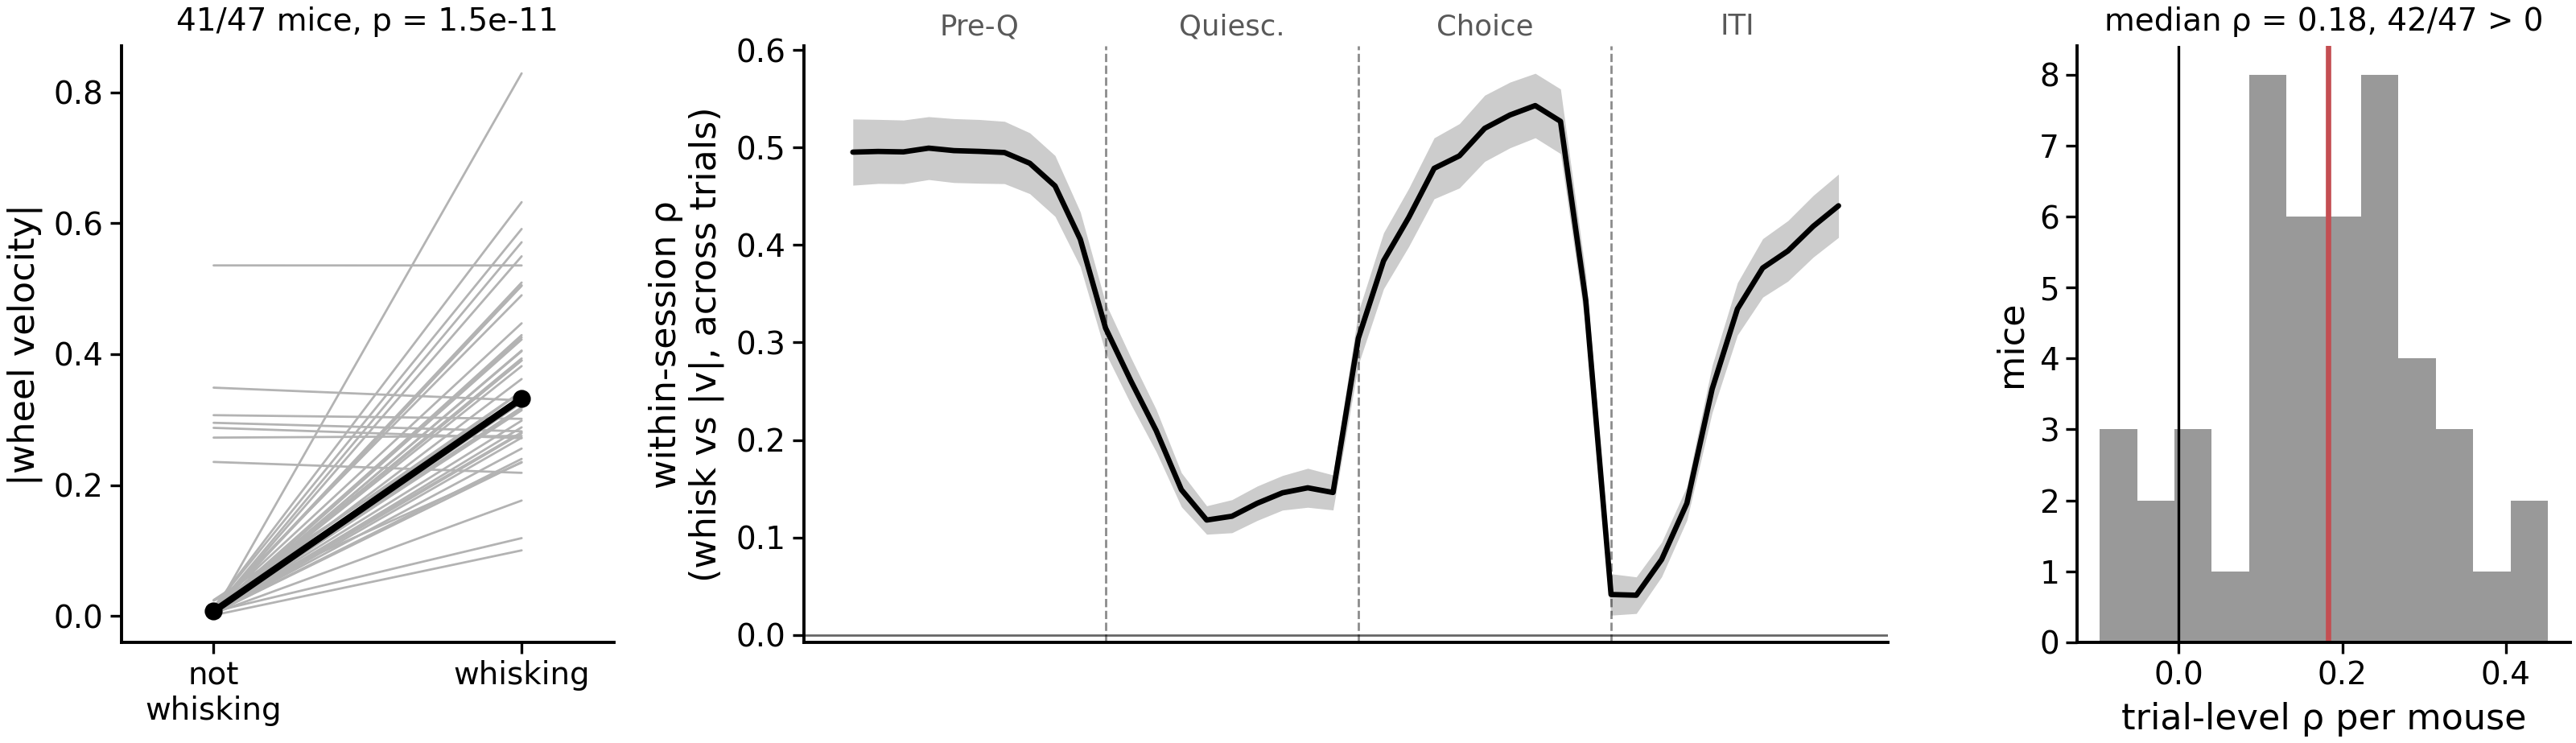

within-session per-bin ρ, mean over mice, by phase:
Pre-quiescence    0.482
Quiescence        0.175
Choice            0.455
ITI               0.302


In [6]:
# (a) wheel speed when whisking vs not, per mouse
paired = pd.DataFrame({m: {'whisking': np.nanmean(V[idx][W[idx] == 1]),
                           'not whisking': np.nanmean(V[idx][W[idx] == 0])}
                       for m, idx in ((m, np.flatnonzero(trials.mouse_name.to_numpy() == m)) for m in mice)}).T

# (b) per-bin, across-trial Spearman within each session
def within_session_bin_rho(W, V, groups, min_n=20):
    out = np.full((len(groups), W.shape[1]), np.nan)
    for i, idx in enumerate(groups):
        for b in range(W.shape[1]):
            w, v = W[idx, b], V[idx, b]
            ok = np.isfinite(w) & np.isfinite(v)
            if ok.sum() >= min_n and 0 < w[ok].mean() < 1:
                out[i, b] = spearmanr(w[ok], v[ok])[0]
    return out

groups = [np.flatnonzero(trials.mouse_name.to_numpy() == m) for m in mice]
R_bin = within_session_bin_rho(W, V, groups)

# (c) trial level: fraction of the trial spent whisking vs mean wheel speed
r_trial = pd.Series({m: spearmanr(trials.whisk_frac.to_numpy()[g], trials.wheel_speed.to_numpy()[g],
                                  nan_policy='omit')[0] for m, g in zip(mice, groups)})

fig, axs = plt.subplots(1, 3, figsize=(8.2, 2.5), gridspec_kw=dict(width_ratios=[1, 2.2, 1]))
ax = axs[0]
for _, r in paired.iterrows():
    ax.plot([0, 1], [r['not whisking'], r['whisking']], color='0.7', lw=0.5)
ax.plot([0, 1], paired[['not whisking', 'whisking']].median(), color='k', lw=1.5, marker='o', ms=3)
ax.set_xticks([0, 1]); ax.set_xticklabels(['not\nwhisking', 'whisking']); ax.set_xlim(-0.3, 1.3)
ax.set_ylabel('|wheel velocity|')
pw = wilcoxon(paired['whisking'], paired['not whisking']).pvalue
ax.set_title(f'{(paired.whisking > paired["not whisking"]).sum()}/{len(paired)} mice, p = {pw:.1e}', fontsize=7)

ax = axs[1]
m_, s_ = np.nanmean(R_bin, 0), np.nanstd(R_bin, 0) / np.sqrt(np.sum(np.isfinite(R_bin), 0))
ax.plot(np.arange(NB), m_, color='k'); ax.fill_between(np.arange(NB), m_ - s_, m_ + s_, color='k', alpha=0.2, lw=0)
ps.zero_line(ax); ps.epoch_lines(ax, NB, label=True, names=ps.EPOCH_SHORT); ax.set_xticks([])
ax.set_ylabel('within-session ρ\n(whisk vs |v|, across trials)')

ax = axs[2]
ax.hist(r_trial, bins=12, color='0.6'); ax.axvline(0, color='k', lw=0.6)
ax.axvline(r_trial.median(), color=WHEEL_C, lw=1.2)
ax.set_xlabel('trial-level ρ per mouse'); ax.set_ylabel('mice')
ax.set_title(f'median ρ = {r_trial.median():.2f}, {(r_trial > 0).sum()}/{len(r_trial)} > 0', fontsize=7)
plt.tight_layout(); plt.show()

print('within-session per-bin ρ, mean over mice, by phase:')
print(pd.Series([np.nanmean(R_bin[:, k * 10:(k + 1) * 10]) for k in range(4)], index=EP).round(3).to_string())

### Between mice: session-level whisking vs session-level wheel movement

`frac_moving` and `mean_speed_moving` are the pre-registered wheel-vigor metrics from
`wheel_vigor.py`, computed on the whole raw session (no warping); `wheel |v| (warped)` is the
mean of the matrix above.

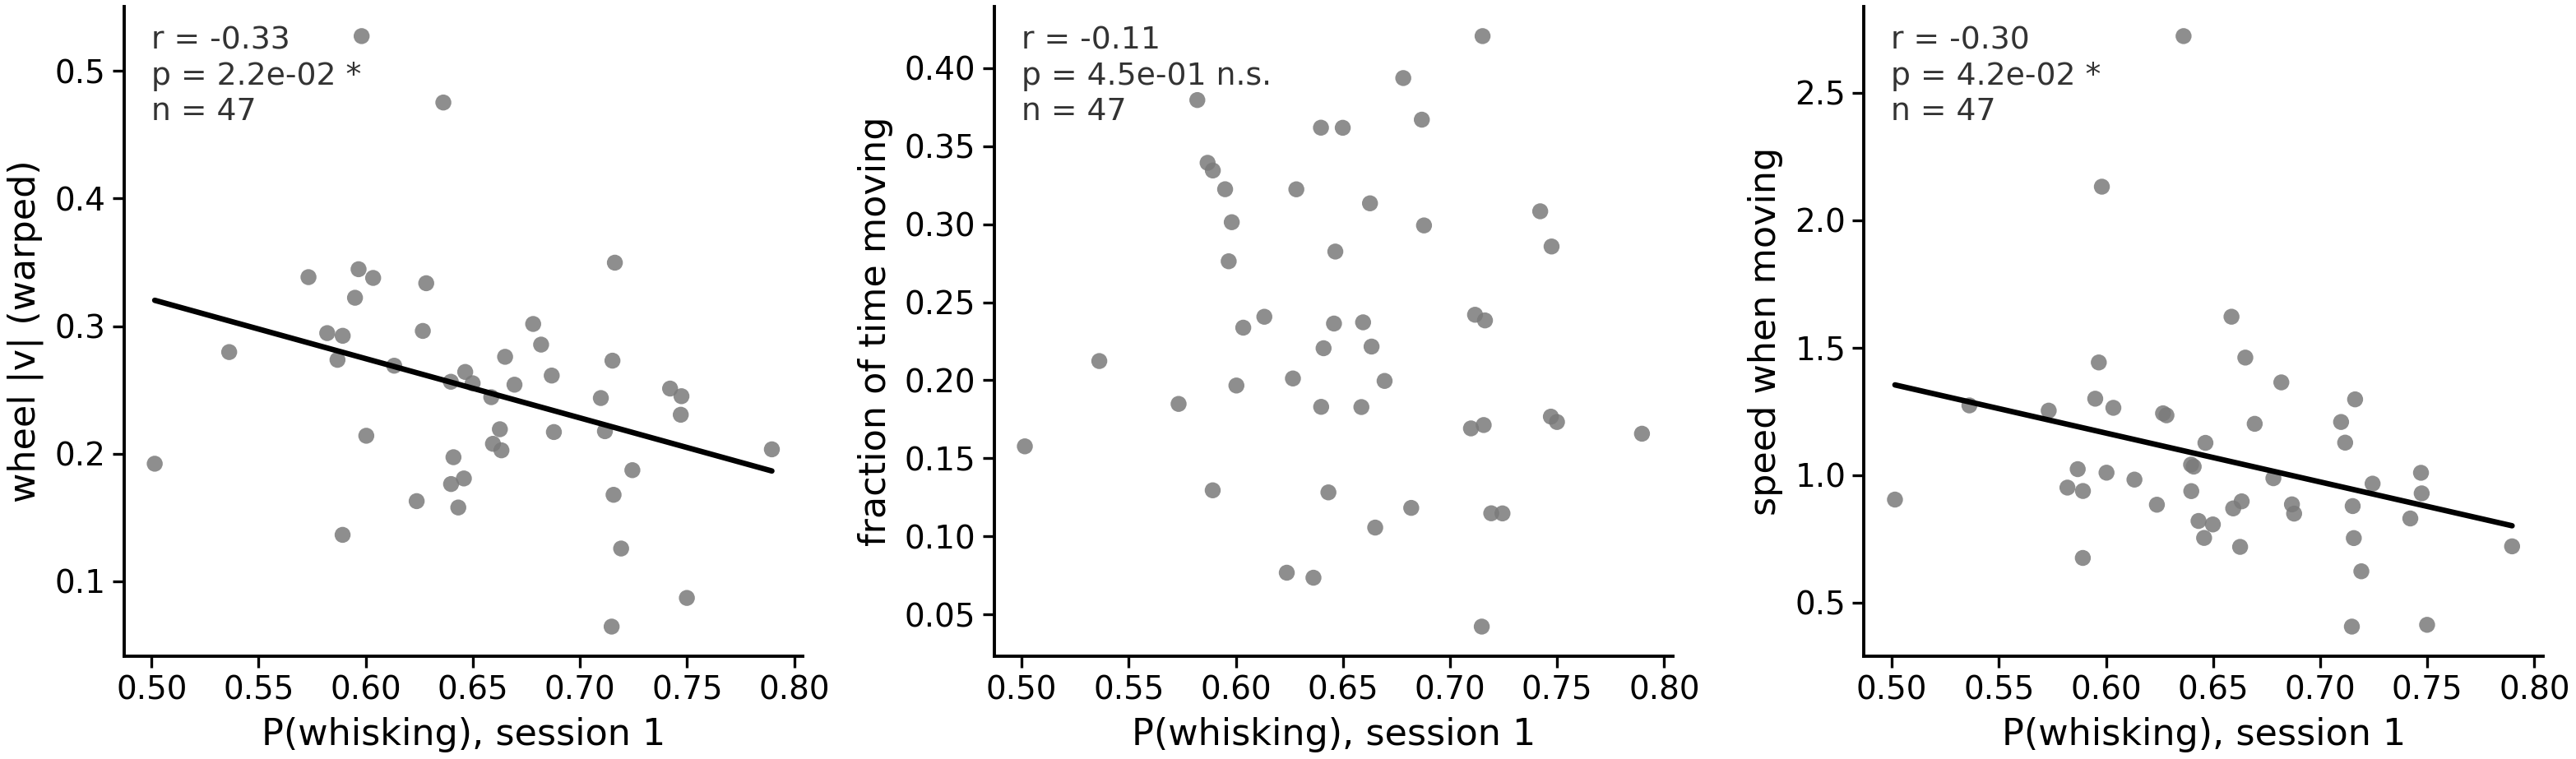

In [7]:
M = pd.DataFrame(index=pd.Index(mice, name='mouse_name'))
M['whisk_early'] = trials.groupby('mouse_name')['whisk_frac'].mean()
for k, ph in enumerate(EP):
    M[f'whisk_{ph}'] = pd.Series({m: np.nanmean(W[g, k * 10:(k + 1) * 10]) for m, g in zip(mice, groups)})
M['wheel_warped'] = trials.groupby('mouse_name')['wheel_speed'].mean()
vig = pd.read_parquet(HERE / 'wheel' / 'vigor_sessions.parquet')
vig = vig[vig.source == 'training'].set_index('mouse_name')
M = M.join(vig[['frac_moving', 'mean_speed_moving', 'duration_min']])
M['n_trials'] = trials.groupby('mouse_name').size()

fig, axs = plt.subplots(1, 3, figsize=(8, 2.5))
for ax, (col, lbl) in zip(axs, [('wheel_warped', 'wheel |v| (warped)'), ('frac_moving', 'fraction of time moving'),
                                ('mean_speed_moving', 'speed when moving')]):
    ps.corr_panel(ax, M['whisk_early'], M[col], color=ps.NEUTRAL, xlabel='P(whisking), session 1', ylabel=lbl)
plt.tight_layout(); plt.show()

**Reading.** Within a session the two are clearly coupled: on the same trial bin, the wheel moves
faster when the mouse is whisking, in essentially every mouse. But *between* mice the sign flips:
mice that whisk a larger fraction of session 1 move the wheel *less* vigorously
(speed-when-moving), and are no different in how much of the time they move it. So
"whisking ≈ wheel movement" is a statement about moment-to-moment co-occurrence, not about
which mice are the movers. This matters for the hypothesis below: a whisking effect on LD1 or
learning cannot be the wheel effect in disguise.

## 4. Whisking vs LD1

Statistics helper: Pearson (the paper's default) and Spearman, plus the **lab-removed**
correlation (both variables residualised on Alyx lab dummies, as in `lab_controls.py`) and,
on rows starting with `|`, a **partial** correlation controlling for a covariate (then `r`/`p` are
the partial r, and `r_lab` removes lab *and* the covariate).

In [8]:
M['LD1'] = lc.LDA.groupby('mouse_name')['LD1'].mean()
M['lab'] = lc.MOUSE_LAB


def resid(v, D):
    return v - D @ np.linalg.lstsq(D, v, rcond=None)[0]


def corr_row(df, x, y, covar=None, label=None):
    cols = [x, y] + ([covar] if covar else [])
    d = df[cols + ['lab']].replace([np.inf, -np.inf], np.nan).dropna(subset=cols)
    r, p = pearsonr(d[x], d[y]); rho, p_s = spearmanr(d[x], d[y])
    out = dict(test=label or f'{x} ~ {y}', n=len(d), r=r, p=p, rho=rho, p_spearman=p_s)
    dl = d.dropna(subset=['lab'])
    D = lc._lab_design(dl['lab'].to_numpy())
    if covar:
        D = np.column_stack([D, dl[covar].to_numpy(float)])
        D0 = np.column_stack([np.ones(len(d)), d[covar].to_numpy(float)])
        ex, ey = resid(d[x].to_numpy(float), D0), resid(d[y].to_numpy(float), D0)
        rp = np.corrcoef(ex, ey)[0, 1]; dof = len(d) - 3
        # a partial row reports the PARTIAL r in r / p (no Spearman); r_lab then removes lab AND the covariate
        out.update(r=rp, p=2 * t_dist.sf(abs(rp) * np.sqrt(dof / (1 - rp ** 2)), dof), rho=np.nan, p_spearman=np.nan)
    ex, ey = resid(dl[x].to_numpy(float), D), resid(dl[y].to_numpy(float), D)
    rl = np.corrcoef(ex, ey)[0, 1]; dof = len(dl) - D.shape[1] - 1
    out.update(r_lab=rl, p_lab=2 * t_dist.sf(abs(rl) * np.sqrt(dof / (1 - rl ** 2)), dof), n_lab=len(dl))
    return out

### Positive control: proficient whisking vs LD1, and session 1 vs proficient whisking

Proficient whisking from the syllable file the current LDA was fitted on
(`8_k_10_bin_syllables_02-10-2026`, LDA sessions only; same code layout, whisk = `(code // 8) % 2`).

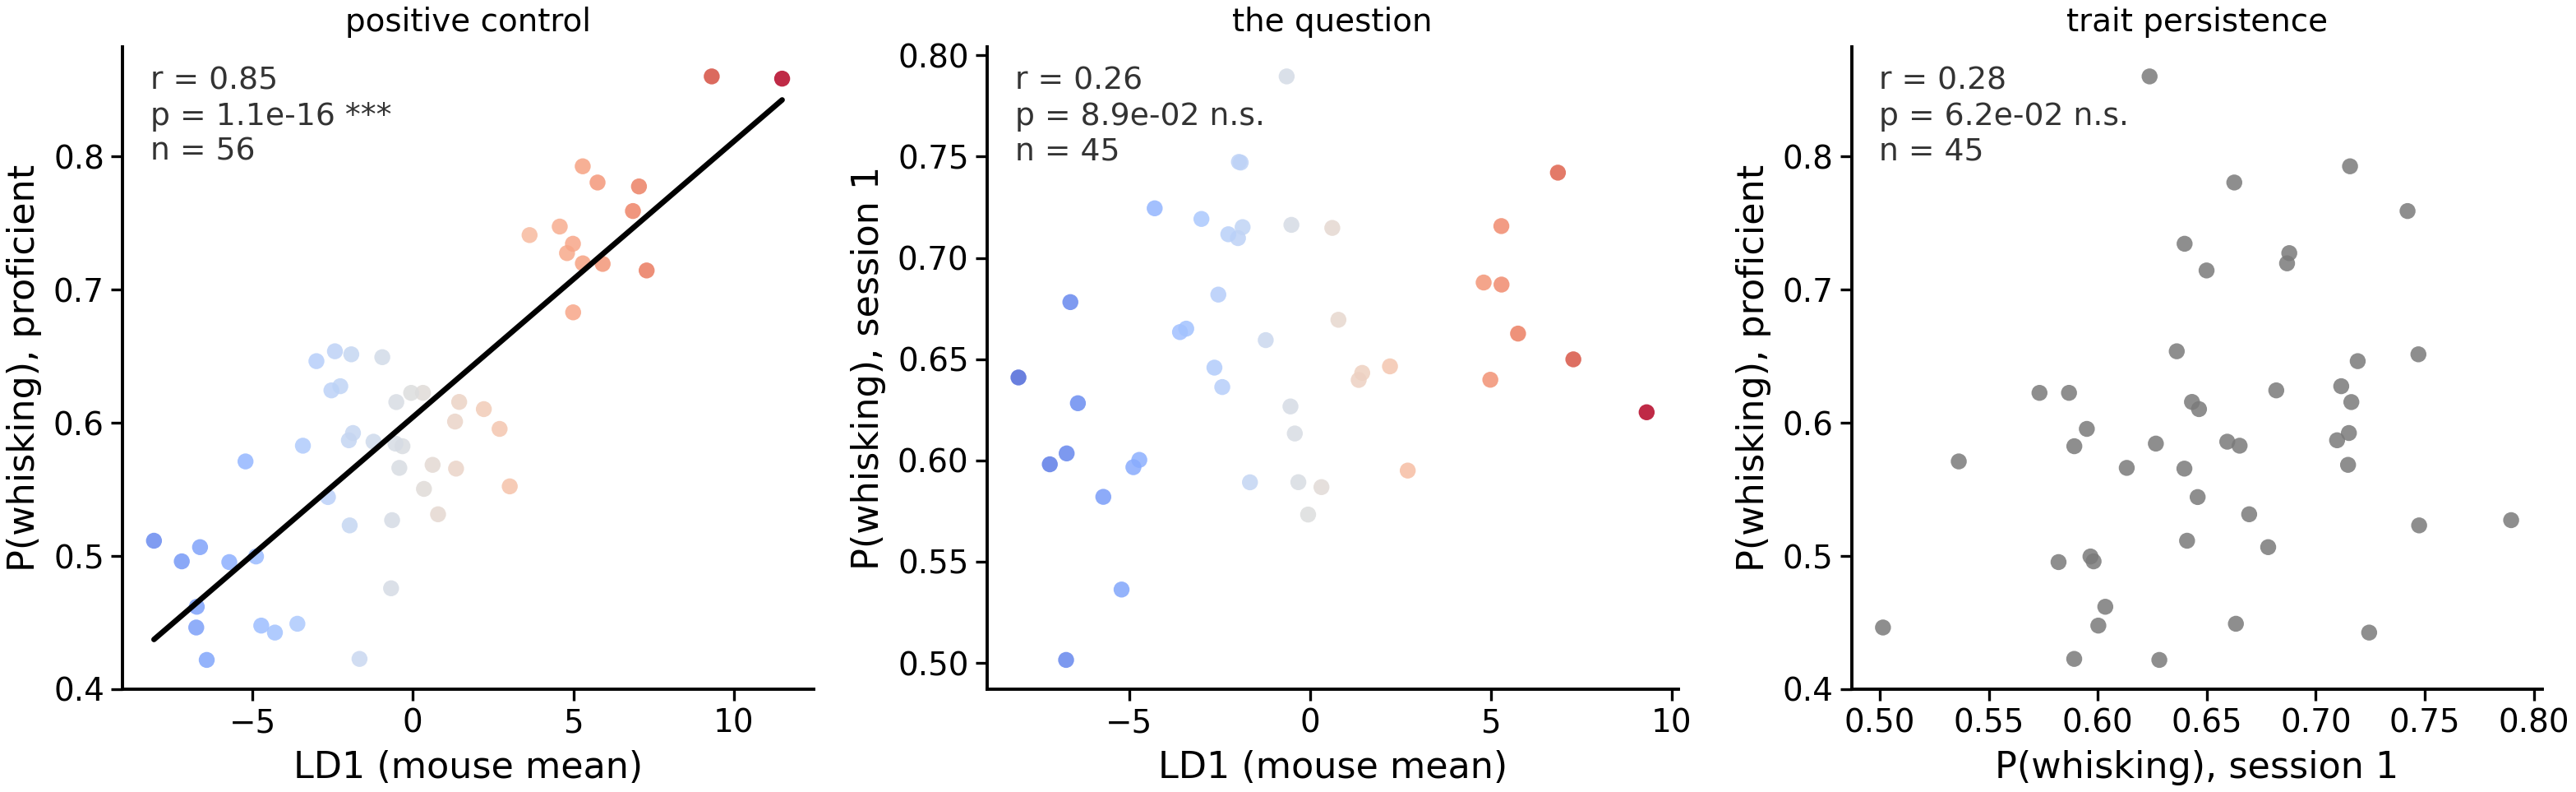

In [9]:
# the Mac keeps it in clustering/data_files/, the linux machine in data/
syl = pd.read_parquet(next(p for p in [PI / 'clustering' / 'data_files' / '8_k_10_bin_syllables_02-10-2026',
                                       PI / 'data' / '8_k_10_bin_syllables_02-10-2026'] if p.exists()))
syl['session'] = syl['sample'].str[:36]
syl = syl[syl.session.isin(set(lc.LDA.session))]
_, whisk_codes, _ = ps.decode_syllables(np.vstack([np.asarray(s, float) for s in syl['binned_sequence']]))
syl['whisk'] = np.nanmean(whisk_codes, axis=1)
prof_sess = syl.groupby(['mouse_name', 'session'])['whisk'].mean().reset_index()

P = pd.DataFrame({'whisk_prof': prof_sess.groupby('mouse_name')['whisk'].mean()})
P['LD1'] = lc.LDA.groupby('mouse_name')['LD1'].mean()
P['lab'] = lc.MOUSE_LAB
M['whisk_prof'] = P['whisk_prof']

fig, axs = plt.subplots(1, 3, figsize=(8, 2.6))
ps.corr_panel(axs[0], P['LD1'], P['whisk_prof'], xlabel='LD1 (mouse mean)', ylabel='P(whisking), proficient')
ps.corr_panel(axs[1], M['LD1'], M['whisk_early'], xlabel='LD1 (mouse mean)', ylabel='P(whisking), session 1')
ps.corr_panel(axs[2], M['whisk_early'], M['whisk_prof'], color=ps.NEUTRAL,
              xlabel='P(whisking), session 1', ylabel='P(whisking), proficient')
axs[0].set_title('positive control', fontsize=7); axs[1].set_title('the question', fontsize=7)
axs[2].set_title('trait persistence', fontsize=7)
plt.tight_layout(); plt.show()

### Session-1 whisking vs LD1, by trial phase, and controlling for wheel movement

In [10]:
rows = [corr_row(P, 'whisk_prof', 'LD1', label='proficient whisking ~ LD1  [positive control]'),
        corr_row(M, 'whisk_early', 'whisk_prof', label='session-1 whisking ~ proficient whisking'),
        corr_row(M, 'whisk_early', 'LD1', label='session-1 whisking ~ LD1'),
        corr_row(M, 'whisk_early', 'LD1', covar='mean_speed_moving', label='  | controlling speed when moving'),
        corr_row(M, 'whisk_early', 'LD1', covar='wheel_warped', label='  | controlling wheel |v| (warped)'),
        corr_row(M, 'wheel_warped', 'LD1', label='session-1 wheel |v| (warped) ~ LD1'),
        corr_row(M, 'frac_moving', 'LD1', label='session-1 fraction moving ~ LD1'),
        corr_row(M, 'mean_speed_moving', 'LD1', label='session-1 speed when moving ~ LD1')]
rows += [corr_row(M, f'whisk_{ph}', 'LD1', label=f'session-1 whisking in {ph} ~ LD1') for ph in EP]
ld1_tab = pd.DataFrame(rows).set_index('test')
show_cols = ['n', 'r', 'p', 'rho', 'p_spearman', 'r_lab', 'p_lab']
ld1_tab[[c for c in show_cols if c in ld1_tab]].round(3)

,n,r,p,rho,p_spearman,r_lab,p_lab
test,,,,,,,
proficient whisking ~ LD1 [positive control],56,0.850,0.000,0.761,0.000,0.860,0.000
session-1 whisking ~ proficient whisking,45,0.280,0.062,0.305,0.042,0.161,0.357
session-1 whisking ~ LD1,45,0.256,0.089,0.206,0.175,0.108,0.535
| controlling speed when moving,45,0.186,0.227,NaN,NaN,0.089,0.618
| controlling wheel |v| (warped),45,0.188,0.221,NaN,NaN,0.061,0.732
session-1 wheel |v| (warped) ~ LD1,45,-0.293,0.051,-0.233,0.124,-0.287,0.095
session-1 fraction moving ~ LD1,45,0.046,0.763,0.102,0.506,0.018,0.917
session-1 speed when moving ~ LD1,45,-0.330,0.027,-0.401,0.006,-0.213,0.220
session-1 whisking in Pre-quiescence ~ LD1,45,0.253,0.093,0.209,0.168,0.078,0.655


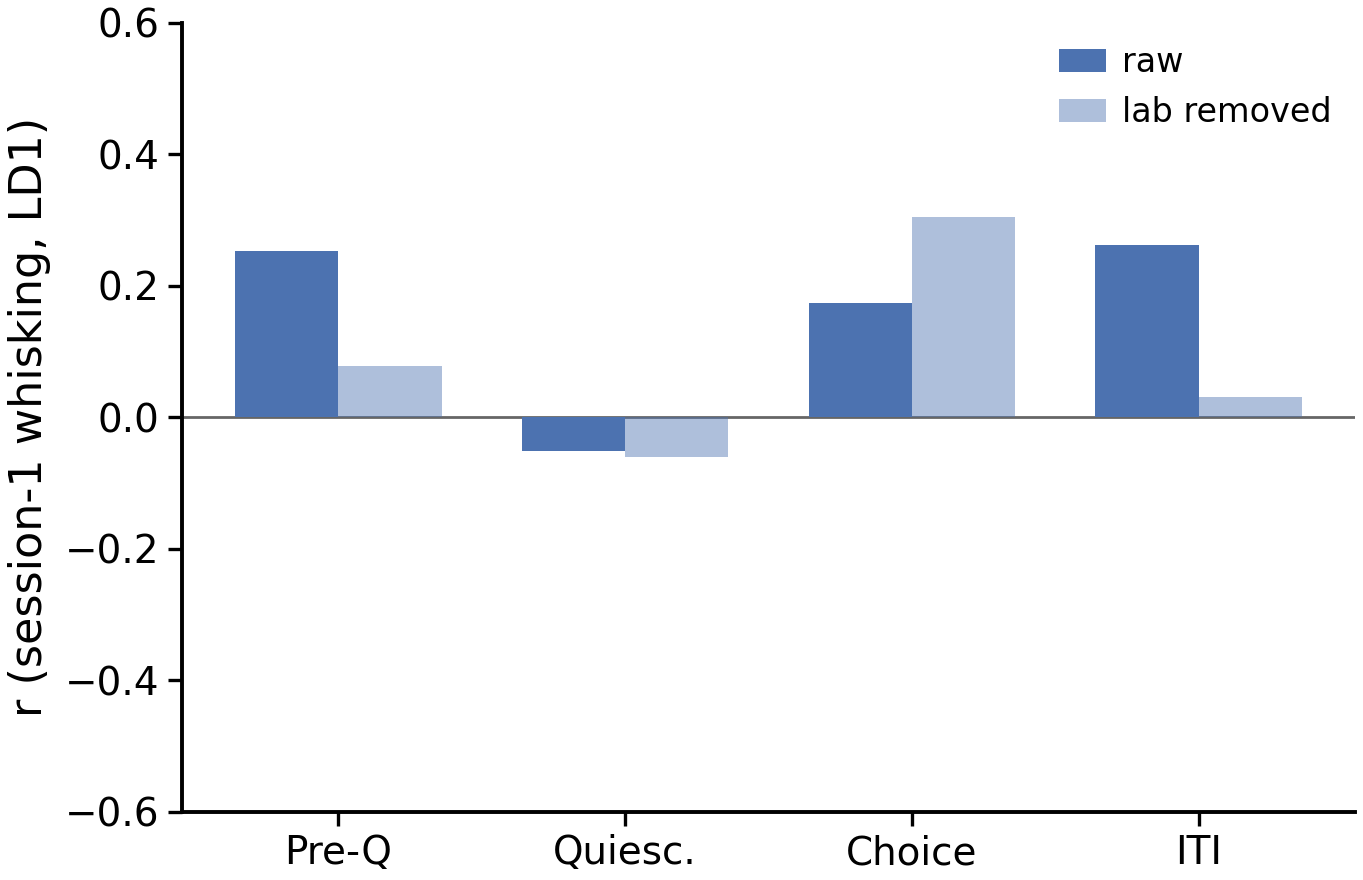

In [11]:
fig, ax = plt.subplots(figsize=(3.6, 2.4))
xs = np.arange(len(EP))
vals = [ld1_tab.loc[f'session-1 whisking in {ph} ~ LD1'] for ph in EP]
ax.bar(xs - 0.18, [v['r'] for v in vals], 0.36, color=WHISK_C, label='raw')
ax.bar(xs + 0.18, [v['r_lab'] for v in vals], 0.36, color=WHISK_C, alpha=0.45, label='lab removed')
for i, v in enumerate(vals):
    ax.text(i - 0.18, v['r'] + 0.02 * np.sign(v['r']), ps.stars(v['p']).replace('n.s.', ''), ha='center', fontsize=7)
ps.zero_line(ax); ax.set_xticks(xs); ax.set_xticklabels(ps.EPOCH_SHORT)
ax.set_ylabel('r (session-1 whisking, LD1)'); ax.legend(fontsize=6, frameon=False)
ax.set_ylim(-0.6, 0.6)
plt.tight_layout(); plt.show()

## 5. Whisking vs learning speed

`log_train` = log(number of training sessions before proficiency); **higher = slower**, so the
engagement hypothesis ("more whisking → faster learning") predicts a **negative** r. LD1 ~
learning speed is included as the reference effect the hypothesis rests on.

**Late** = the last training session. Its whisking sits right before proficiency, so it is closer
to an outcome measure than a predictor; it is shown because the hypothesis names it, not as a
test of prediction.

In [12]:
tt = pd.read_parquet(PI.parent / 'learning_prediction' / 'training_time_05-05-2026').set_index('mouse_name')
excluded = tt.index[np.log(tt['training_days']).isin([0, 1])]          # as lab_controls (PL034)
LS = np.log(tt['training_days'].drop(excluded)).rename('log_train')
M['log_train'] = LS

L = pd.DataFrame({'whisk_late': late_trials.groupby('mouse_name')['whisk_frac'].mean()})
L['log_train'] = LS; L['LD1'] = lc.LDA.groupby('mouse_name')['LD1'].mean(); L['lab'] = lc.MOUSE_LAB
L['whisk_early'] = M['whisk_early']

A = pd.DataFrame({'LD1': lc.LDA.groupby('mouse_name')['LD1'].mean(), 'log_train': LS, 'lab': lc.MOUSE_LAB})

rows = [corr_row(A, 'LD1', 'log_train', label='LD1 ~ learning speed  [reference]'),
        corr_row(M, 'whisk_early', 'log_train', label='session-1 whisking ~ learning speed'),
        corr_row(M, 'whisk_early', 'log_train', covar='mean_speed_moving', label='  | controlling speed when moving'),
        corr_row(M, 'whisk_early', 'log_train', covar='LD1', label='  | controlling LD1'),
        corr_row(M, 'wheel_warped', 'log_train', label='session-1 wheel |v| (warped) ~ learning speed'),
        corr_row(M, 'frac_moving', 'log_train', label='session-1 fraction moving ~ learning speed'),
        corr_row(M, 'whisk_prof', 'log_train', label='proficient whisking ~ learning speed'),
        corr_row(L, 'whisk_late', 'log_train', label='last-training whisking ~ learning speed'),
        corr_row(L, 'whisk_late', 'LD1', label='last-training whisking ~ LD1'),
        corr_row(L, 'whisk_early', 'whisk_late', label='session-1 ~ last-training whisking')]
rows += [corr_row(M, f'whisk_{ph}', 'log_train', label=f'session-1 whisking in {ph} ~ learning speed') for ph in EP]
ls_tab = pd.DataFrame(rows).set_index('test')
ls_tab[[c for c in show_cols if c in ls_tab]].round(3)

,n,r,p,rho,p_spearman,r_lab,p_lab
test,,,,,,,
LD1 ~ learning speed [reference],54,-0.341,0.012,-0.296,0.030,-0.378,0.011
session-1 whisking ~ learning speed,47,-0.144,0.333,-0.112,0.452,-0.211,0.225
| controlling speed when moving,47,-0.093,0.538,NaN,NaN,-0.214,0.225
| controlling LD1,45,-0.018,0.908,NaN,NaN,-0.182,0.303
session-1 wheel |v| (warped) ~ learning speed,47,0.167,0.262,0.261,0.076,0.046,0.793
session-1 fraction moving ~ learning speed,47,-0.026,0.863,-0.020,0.893,0.112,0.522
proficient whisking ~ learning speed,45,-0.244,0.107,-0.197,0.193,-0.380,0.024
last-training whisking ~ learning speed,53,-0.174,0.213,-0.113,0.422,-0.160,0.318
last-training whisking ~ LD1,53,0.398,0.003,0.344,0.012,0.339,0.026


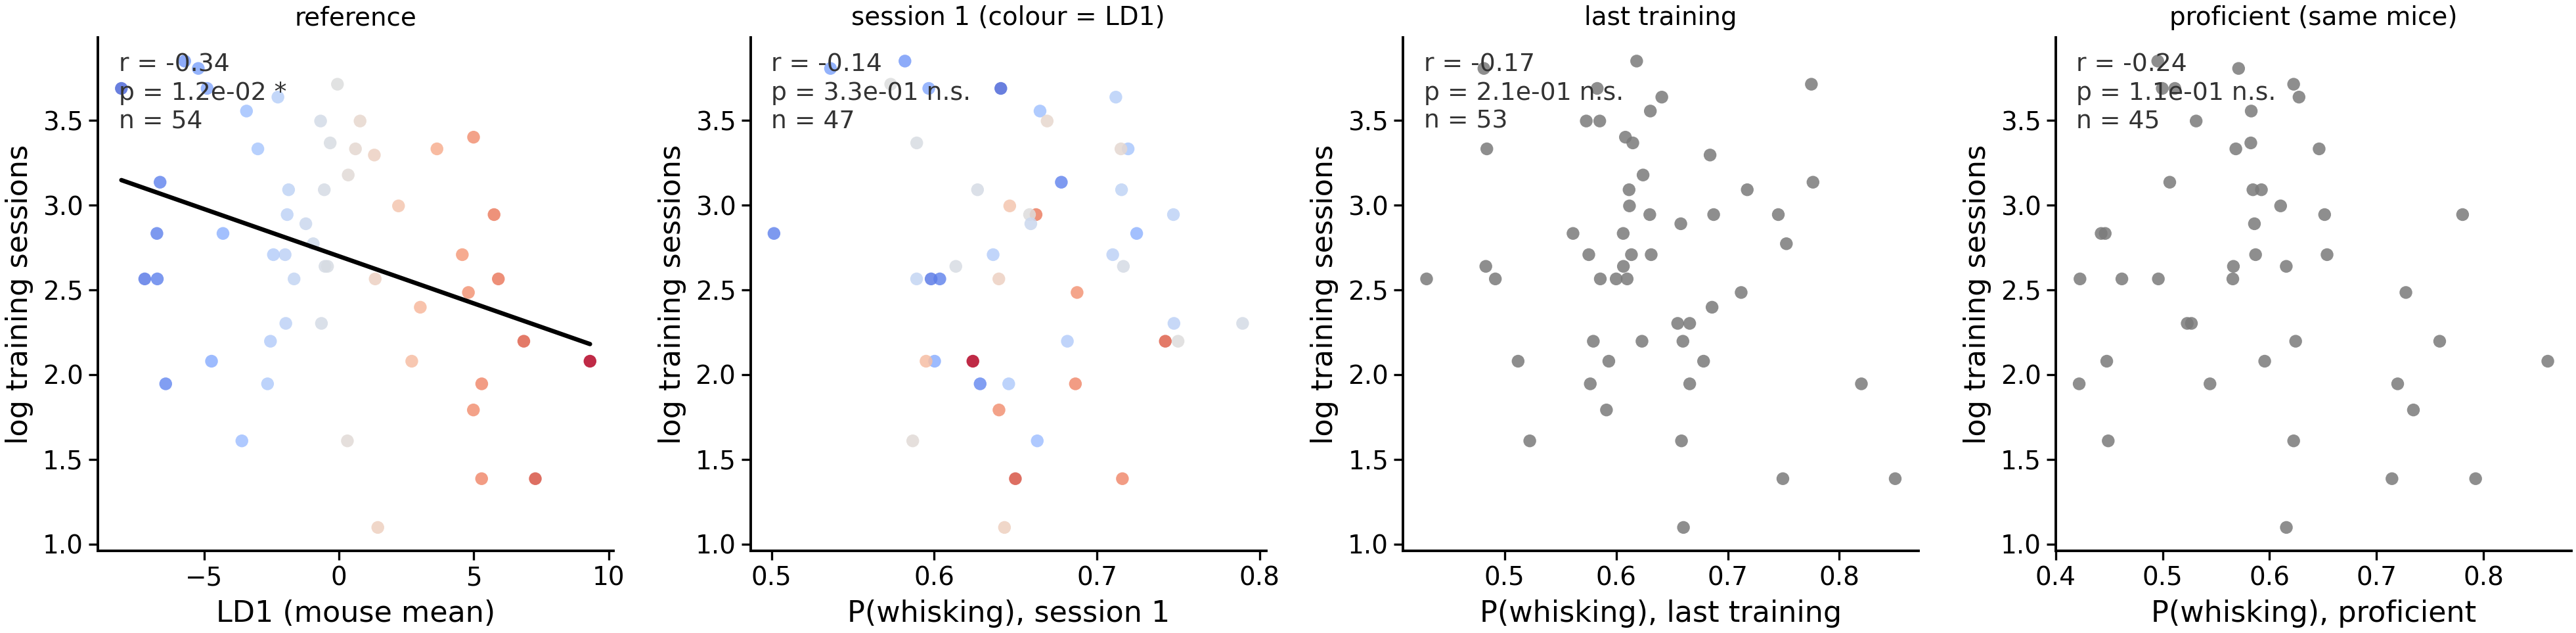

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(10, 2.6))
ps.corr_panel(axs[0], A['LD1'], A['log_train'], xlabel='LD1 (mouse mean)', ylabel='log training sessions')
ps.corr_panel(axs[1], M['whisk_early'], M['log_train'], color=ps.ld1_colors(M['LD1'].fillna(0)),
              xlabel='P(whisking), session 1', ylabel='log training sessions')
ps.corr_panel(axs[2], L['whisk_late'], L['log_train'], color=ps.NEUTRAL,
              xlabel='P(whisking), last training', ylabel='log training sessions')
ps.corr_panel(axs[3], M['whisk_prof'], M['log_train'], color=ps.NEUTRAL,
              xlabel='P(whisking), proficient', ylabel='log training sessions')
for ax, t in zip(axs, ['reference', 'session 1 (colour = LD1)', 'last training', 'proficient (same mice)']):
    ax.set_title(t, fontsize=7)
plt.tight_layout(); plt.show()

## 6. All tests together

Exploratory family: everything in the two tables except the positive control and the reference
line. Benjamini–Hochberg across that family, on the Pearson p (the paper's default).

In [14]:
allt = pd.concat([ld1_tab.assign(outcome='LD1'), ls_tab.assign(outcome='learning speed')]).reset_index()
fam = ~allt['test'].str.contains(r'\[')
allt.loc[fam, 'q_BH'] = multipletests(allt.loc[fam, 'p'], method='fdr_bh')[1]
allt = allt.set_index(['outcome', 'test'])

# detectable effect at 80% power, two-tailed alpha .05, n = 45 (Fisher z)
from scipy.stats import norm
n0 = 45
r80 = np.tanh((norm.ppf(0.975) + norm.ppf(0.8)) / np.sqrt(n0 - 3))
print(f'smallest |r| detectable with 80% power at n = {n0}: {r80:.2f}')
allt[['n', 'r', 'p', 'q_BH', 'rho', 'r_lab', 'p_lab']].round(3)

smallest |r| detectable with 80% power at n = 45: 0.41


n      r  \
outcome        test                                                            
LD1            proficient whisking ~ LD1  [positive control]       56  0.850   
               session-1 whisking ~ proficient whisking            45  0.280   
               session-1 whisking ~ LD1                            45  0.256   
                 | controlling speed when moving                   45  0.186   
                 | controlling wheel |v| (warped)                  45  0.188   
               session-1 wheel |v| (warped) ~ LD1                  45 -0.293   
               session-1 fraction moving ~ LD1                     45  0.046   
               session-1 speed when moving ~ LD1                   45 -0.330   
               session-1 whisking in Pre-quiescence ~ LD1          45  0.253   
               session-1 whisking in Quiescence ~ LD1              45 -0.051   
               session-1 whisking in Choice ~ LD1                  45  0.175   
               session-1 whisking in ITI ~ LD1                     45  0.263   
learning speed LD1 ~ learning speed  [reference]                   54 -0.341   
               session-1 whisking ~ learning speed                 47 -0.144   
                 | controlling speed when moving                   47 -0.093   
                 | controlling LD1                                 45 -0.018   
               session-1 wheel |v| (warped) ~ learning speed       47  0.167   
               session-1 fraction moving ~ learning speed          47 -0.026   
               proficient whisking ~ learning speed                45 -0.244   
               last-training whisking ~ learning speed             53 -0.174   
               last-training whisking ~ LD1                        53  0.398   
               session-1 ~ last-training whisking                  45  0.364   
               session-1 whisking in Pre-quiescence ~ learning...  47 -0.111   
               session-1 whisking in Quiescence ~ learning speed   47 -0.060   
               session-1 whisking in Choice ~ learning speed       47 -0.169   
               session-1 whisking in ITI ~ learning speed          47 -0.067   

                                                                       p  \
outcome        test                                                        
LD1            proficient whisking ~ LD1  [positive control]       0.000   
               session-1 whisking ~ proficient whisking            0.062   
               session-1 whisking ~ LD1                            0.089   
                 | controlling speed when moving                   0.227   
                 | controlling wheel |v| (warped)                  0.221   
               session-1 wheel |v| (warped) ~ LD1                  0.051   
               session-1 fraction moving ~ LD1                     0.763   
               session-1 speed when moving ~ LD1                   0.027   
               session-1 whisking in Pre-quiescence ~ LD1          0.093   
               session-1 whisking in Quiescence ~ LD1              0.740   
               session-1 whisking in Choice ~ LD1                  0.251   
               session-1 whisking in ITI ~ LD1                     0.081   
learning speed LD1 ~ learning speed  [reference]                   0.012   
               session-1 whisking ~ learning speed                 0.333   
                 | controlling speed when moving                   0.538   
                 | controlling LD1                                 0.908   
               session-1 wheel |v| (warped) ~ learning speed       0.262   
               session-1 fraction moving ~ learning speed          0.863   
               proficient whisking ~ learning speed                0.107   
               last-training whisking ~ learning speed             0.213   
               last-training whisking ~ LD1                        0.003   
               session-1 ~ last-training whisking                  0.014   
   

## 7. Session-1 syllable probability per trial epoch vs learning speed

Every syllable feature in the session-1 file (8 paw-wheel states, whisking, licking): the fraction of
each epoch's bins the mouse spends in it, averaged over trials. That gives a 10 × 4 matrix per
mouse, and each cell is correlated with log(training sessions). **Negative r = more use → faster
learning.**

* **Paw-wheel state numbers are the legacy file's own labels.** That file relabelled its states,
  so they are **not** the vigor order `paper_style` uses for the new files. To make them readable,
  each state is labelled with the mean |wheel velocity| in its bins, taken from the aligned wheel
  matrix built above.
* **Cohorts:** all 47 mice, as in the sections above, and the 37 that pass the paper's session QC
  (`session_filters.exclusions_by_timepoint('filtered_out')`, the cohort of
  `syllable_use_vs_learning_speed.ipynb`). For the QC cohort, the lab-removed r is shown too.
* **Inference:** 40 cells, so BH correction runs within each panel. `*` = raw p < 0.05, `**` = q < 0.05.
  At n = 37 only |r| ≳ 0.44 is detectable with 80% power.

In [15]:
from session_filters import exclusions_by_timepoint

FEATS = [f'Paw-wheel {i}' for i in range(wd.K_PAW)] + ['Whisk', 'Lick']
syl1 = pd.read_parquet(wd.SYL_FILES['Early'])
syl1['session'] = syl1['sample'].str[:36]
syl1['trial_id'] = syl1['sample'].str[37:].astype(float).astype(int)
codes1 = np.vstack([np.asarray(x, float) for x in syl1['binned_sequence']])
paw1, whisk1, lick1 = ps.decode_syllables(codes1, wd.K_PAW)

# one-hot per bin -> fraction of the epoch's 10 bins in each feature, per (trial, epoch)
occ = np.stack([np.where(np.isnan(paw1), np.nan, paw1 == k) for k in range(wd.K_PAW)] + [whisk1, lick1], axis=-1)
occ = np.nanmean(occ, axis=1)                                   # (rows, 10 features)
O = pd.DataFrame(occ, columns=FEATS)
O[['mouse_name', 'session', 'epoch']] = syl1[['mouse_name', 'session', 'broader_label']].to_numpy()
OCC = O.groupby(['mouse_name', 'epoch'])[FEATS].mean().unstack('epoch')      # mouse x (feature, epoch)
OCC = OCC.reindex(columns=pd.MultiIndex.from_product([FEATS, EP]))

# legacy paw-wheel state -> mean |wheel velocity| in its bins (same warped grid as V)
PAW_ROWS = np.full_like(W, np.nan)
pos = {(s, t): i for i, (s, t) in enumerate(zip(trials['session'], trials['trial_id']))}
for (s, t, ph), p_ in zip(syl1[['session', 'trial_id', 'broader_label']].itertuples(index=False), paw1):
    k = EP.index(ph); PAW_ROWS[pos[(s, t)], k * 10:(k + 1) * 10] = p_
state_speed = pd.Series({k: np.nanmean(V[PAW_ROWS == k]) for k in range(wd.K_PAW)})
state_frac = pd.Series({k: np.nanmean(PAW_ROWS == k) for k in range(wd.K_PAW)})
FEAT_LABEL = {f'Paw-wheel {k}': f'PW {k}  (|v| {state_speed[k]:.2f}, {state_frac[k]:.0%})' for k in range(wd.K_PAW)}
FEAT_LABEL.update(Whisk='Whisk', Lick='Lick')
print('legacy paw-wheel states: mean |wheel velocity| in their bins and share of all bins')
print(pd.DataFrame({'wheel |v|': state_speed, 'share': state_frac}).round(3).to_string())

qc_out = set(exclusions_by_timepoint('filtered_out')['Early'])
mouse_session = syl1.drop_duplicates('mouse_name').set_index('mouse_name')['session']
QC_MICE = [m for m in OCC.index if mouse_session[m] not in qc_out]
print(f'\n{len(OCC)} mice; {len(QC_MICE)} pass session QC')

legacy paw-wheel states: mean |wheel velocity| in their bins and share of all bins
   wheel |v|  share
0      0.027  0.207
1      0.072  0.375
2      0.178  0.109
3      0.627  0.110
4      0.551  0.057
5      0.796  0.038
6      1.495  0.027
7      1.297  0.020

47 mice; 37 pass session QC


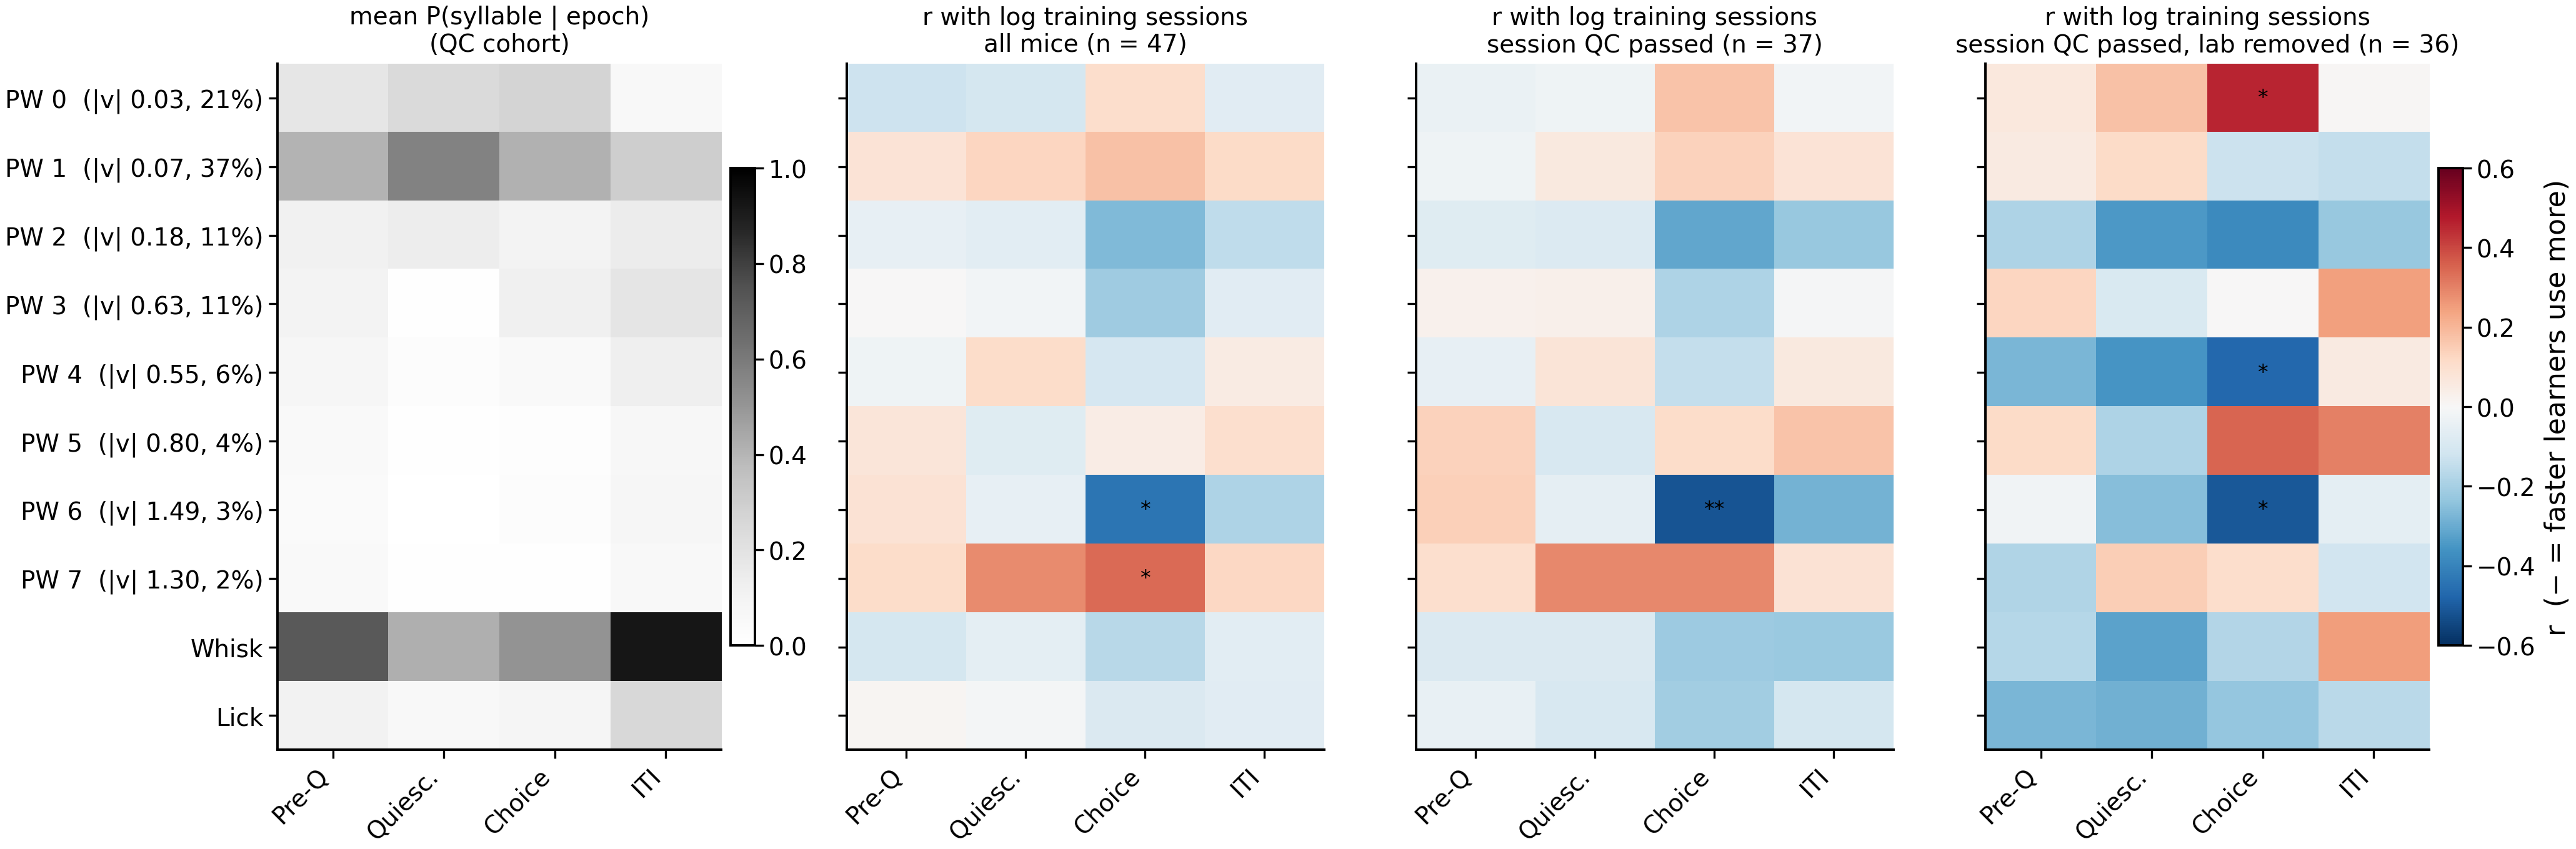

cells with raw p < 0.05 in any panel:


all mice (n = 47)               session QC passed         \
                                   r      p      q                 r      p   
feature     epoch                                                             
Paw-wheel 0 Choice             0.106  0.479  0.882             0.171  0.310   
Paw-wheel 4 Choice            -0.099  0.508  0.882            -0.142  0.403   
Paw-wheel 6 Choice            -0.438  0.002  0.084            -0.518  0.001   
Paw-wheel 7 Choice             0.339  0.020  0.399             0.286  0.086   

                          session QC passed, lab removed                
                        q                              r      p      q  
feature     epoch                                                       
Paw-wheel 0 Choice  0.926                          0.457  0.017  0.222  
Paw-wheel 4 Choice  0.926                         -0.473  0.013  0.222  
Paw-wheel 6 Choice  0.041                         -0.508  0.007  0.222  
Paw-wheel 7 Choice  0.729                          0.104  0.607  0.758

In [16]:
def corr_grid(mice_, lab_removed=False):
    # r, p, q (BH within the grid) of every (feature, epoch) occupancy against log_train
    y = LS.reindex(mice_)
    labs = lc.MOUSE_LAB.reindex(mice_)
    R = pd.DataFrame(index=FEATS, columns=EP, dtype=float); Pv = R.copy(); N = R.copy()
    for f in FEATS:
        for e in EP:
            x = OCC.loc[mice_, (f, e)]
            ok = x.notna() & y.notna() & (labs.notna() if lab_removed else True)
            xv, yv = x[ok].to_numpy(float), y[ok].to_numpy(float)
            if lab_removed:
                D = lc._lab_design(labs[ok].to_numpy())
                xv, yv = resid(xv, D), resid(yv, D)
                r = np.corrcoef(xv, yv)[0, 1]; dof = ok.sum() - D.shape[1] - 1
                p = 2 * t_dist.sf(abs(r) * np.sqrt(dof / (1 - r ** 2)), dof)
            else:
                r, p = pearsonr(xv, yv)
            R.loc[f, e], Pv.loc[f, e], N.loc[f, e] = r, p, ok.sum()
    Q = pd.DataFrame(multipletests(Pv.to_numpy().ravel(), method='fdr_bh')[1].reshape(Pv.shape),
                     index=FEATS, columns=EP)
    return R, Pv, Q, int(N.min().min())


grids = {f'all mice (n = {len(OCC)})': corr_grid(list(OCC.index)),
         f'session QC passed': corr_grid(QC_MICE),
         f'session QC passed, lab removed': corr_grid(QC_MICE, lab_removed=True)}

fig, axs = plt.subplots(1, 4, figsize=(10.5, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1]))
mean_occ = OCC.loc[QC_MICE].mean().unstack()[EP].reindex(FEATS)
im0 = axs[0].imshow(mean_occ.to_numpy(float), cmap='Greys', vmin=0, vmax=1, aspect='auto')
axs[0].set_title('mean P(syllable | epoch)\n(QC cohort)', fontsize=7)
plt.colorbar(im0, ax=axs[0], fraction=0.05, pad=0.02)
for ax, (name, (R, Pv, Q, n)) in zip(axs[1:], grids.items()):
    im = ax.imshow(R.to_numpy(float), cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
    for i, f in enumerate(FEATS):
        for j, e in enumerate(EP):
            mark = '**' if Q.loc[f, e] < 0.05 else ('*' if Pv.loc[f, e] < 0.05 else '')
            ax.text(j, i, mark, ha='center', va='center', fontsize=6, color='k')
    ax.set_title(f'r with log training sessions\n{name}' + ('' if 'all' in name else f' (n = {n})'), fontsize=7)
plt.colorbar(im, ax=axs[-1], fraction=0.05, pad=0.02, label='r  (− = faster learners use more)')
for k, ax in enumerate(axs):
    ax.set_xticks(range(len(EP))); ax.set_xticklabels(ps.EPOCH_SHORT, rotation=45, ha='right')
    ax.set_yticks(range(len(FEATS)))
    ax.set_yticklabels([FEAT_LABEL[f] for f in FEATS] if k == 0 else [])
plt.tight_layout(); plt.show()

tab = pd.concat({name: pd.DataFrame({'r': R.stack(), 'p': Pv.stack(), 'q': Q.stack()})
                 for name, (R, Pv, Q, n) in grids.items()}, axis=1)
tab.index.names = ['feature', 'epoch']
print('cells with raw p < 0.05 in any panel:')
tab[(tab.xs('p', axis=1, level=1) < 0.05).any(axis=1)].round(3)

### Finer view: bin-by-bin correlation with learning speed

The same correlation at each of the 40 warped bins (QC cohort). The band is the 95% range of a null
in which learning speed is shuffled across mice, taken pointwise, so expect about 2 of 40 bins
outside it by chance.

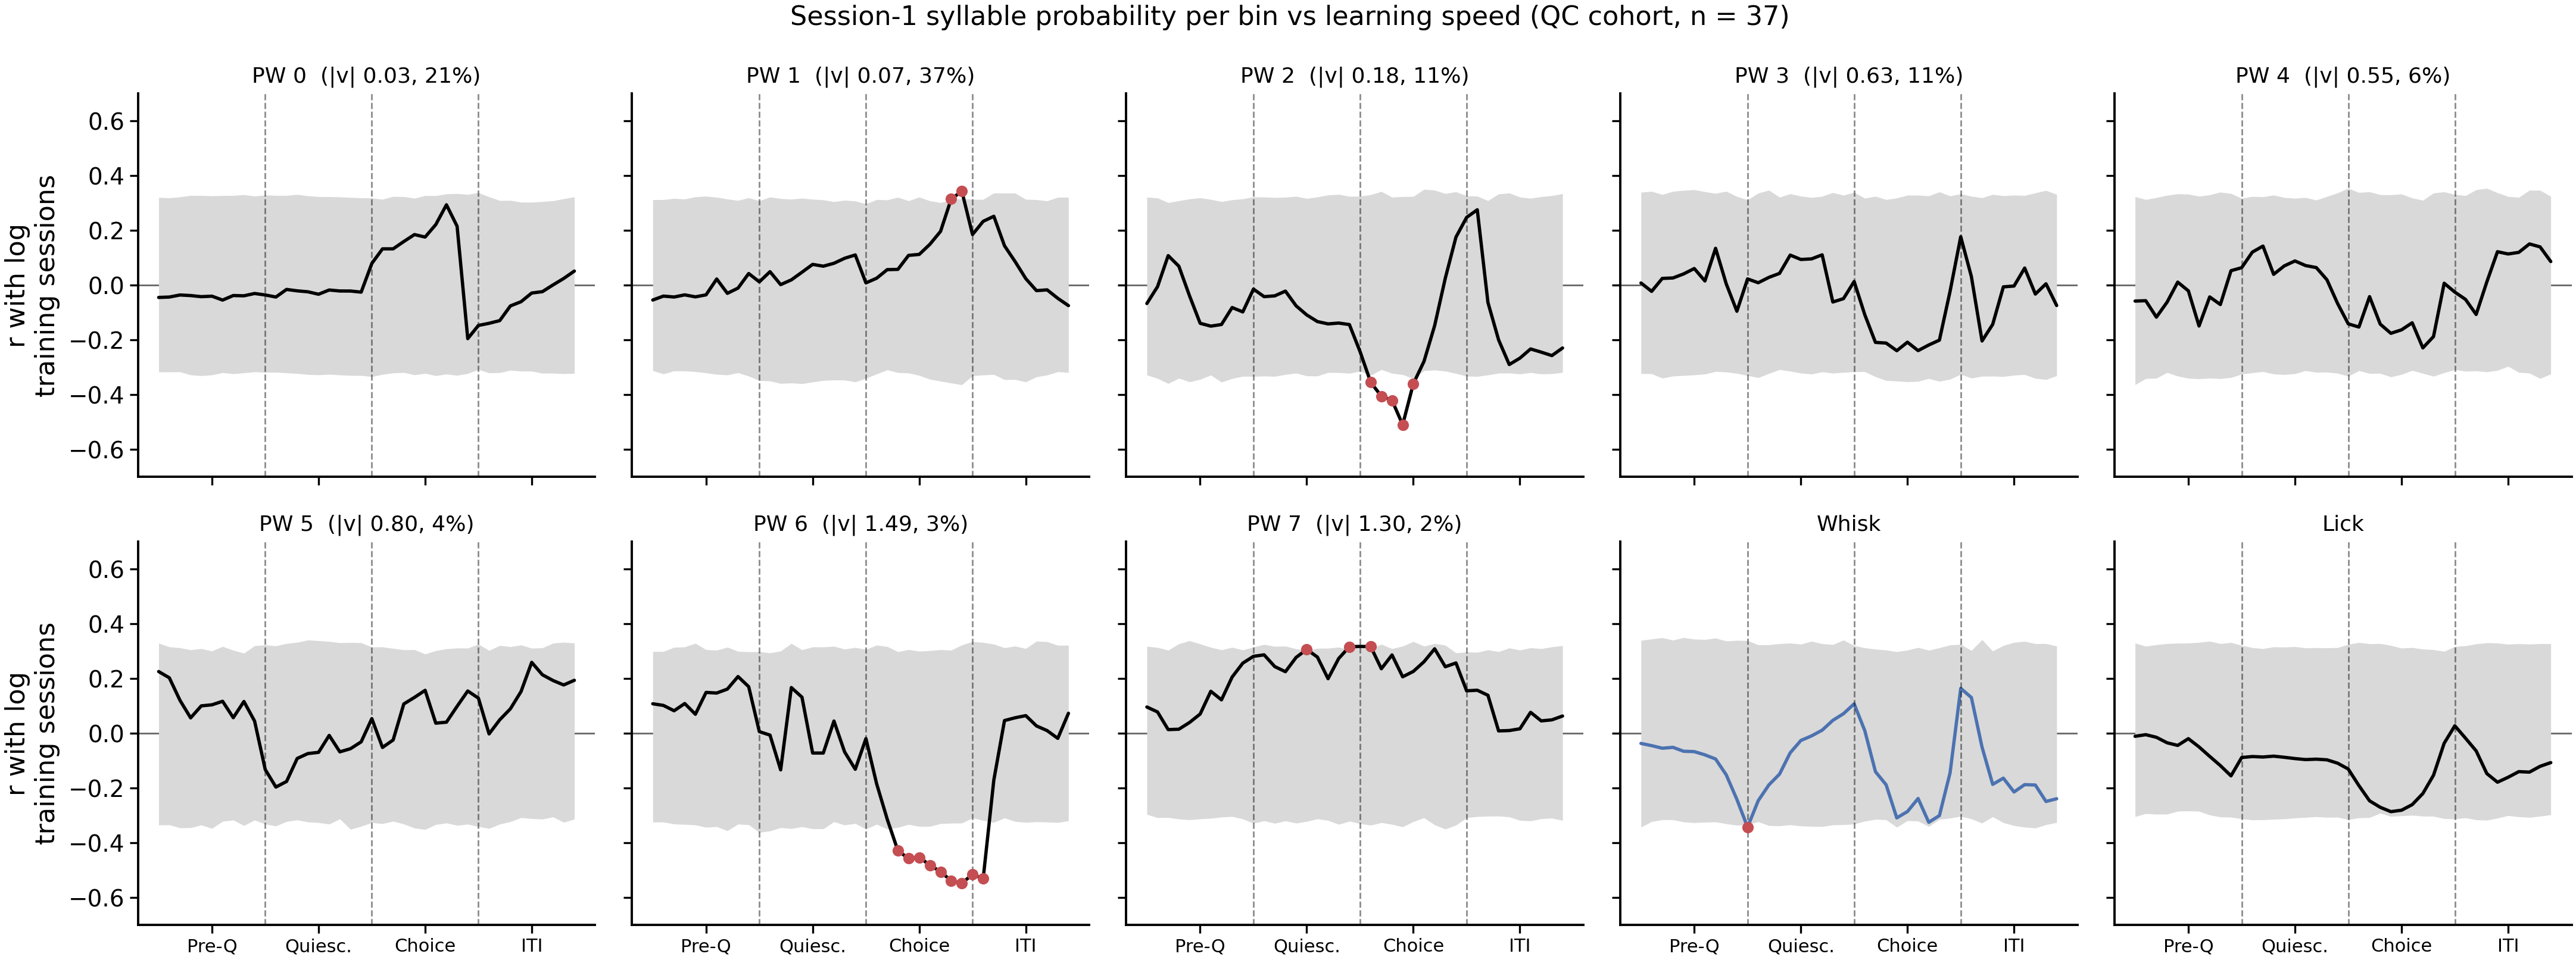

In [17]:
rng = np.random.default_rng(0)
mice_q = [m for m in QC_MICE if np.isfinite(LS.get(m, np.nan))]
yq = LS.reindex(mice_q).to_numpy(float)
idx_m = {m: np.flatnonzero(trials.mouse_name.to_numpy() == m) for m in mice_q}
onehot = {f'Paw-wheel {k}': (PAW_ROWS == k).astype(float) for k in range(wd.K_PAW)}
onehot.update(Whisk=W, Lick=np.full_like(W, np.nan))
# licking on the same 40-bin grid
LICK_ROWS = np.full_like(W, np.nan)
for (s, t, ph), l_ in zip(syl1[['session', 'trial_id', 'broader_label']].itertuples(index=False), lick1):
    k = EP.index(ph); LICK_ROWS[pos[(s, t)], k * 10:(k + 1) * 10] = l_
onehot['Lick'] = LICK_ROWS
for k in range(wd.K_PAW):
    onehot[f'Paw-wheel {k}'][np.isnan(PAW_ROWS)] = np.nan


def zcorr(X, y):
    Xz = (X - X.mean(0)) / X.std(0); yz = (y - y.mean()) / y.std()
    return (Xz * yz[:, None]).mean(0)


fig, axs = plt.subplots(2, 5, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, f in zip(axs.ravel(), FEATS):
    Pm = np.vstack([np.nanmean(onehot[f][idx_m[m]], 0) for m in mice_q])
    r = zcorr(Pm, yq)
    null = np.vstack([zcorr(Pm, rng.permutation(yq)) for _ in range(1000)])
    lo, hi = np.nanpercentile(null, [2.5, 97.5], axis=0)
    ax.fill_between(np.arange(NB), lo, hi, color='0.85', lw=0)
    ax.plot(np.arange(NB), r, color=WHISK_C if f == 'Whisk' else 'k', lw=1)
    out = (r < lo) | (r > hi)
    ax.scatter(np.flatnonzero(out), r[out], s=6, color=WHEEL_C, zorder=3)
    ps.zero_line(ax); ps.epoch_lines(ax, NB)
    ax.set_title(FEAT_LABEL[f], fontsize=6.5); ax.set_ylim(-0.7, 0.7); ax.set_xticks([5, 15, 25, 35])
    ax.set_xticklabels(ps.EPOCH_SHORT, fontsize=5.5)
for ax in axs[:, 0]:
    ax.set_ylabel('r with log\ntraining sessions')
fig.suptitle(f'Session-1 syllable probability per bin vs learning speed (QC cohort, n = {len(mice_q)})', fontsize=8)
plt.tight_layout(); plt.show()

## 7b. Session-1 wheel velocity per bin vs learning speed

**Warped:** each mouse's mean |wheel velocity| at each of the 40 bins (the `V` matrix from section 1,
on the same grid as the syllables), correlated with log(training sessions). The grey band is the
pointwise 95% range when learning speed is shuffled across mice. The top row shows the profile for
the fastest and slowest learning-speed terciles.

**Unwarped:** warping stretches each phase to 10 bins, which can hide timing differences such as
reaction time. So the same correlation is also shown in real time, with |v| aligned to the go cue
and to first movement (raw design matrix, 30 Hz, mean over trials per mouse).

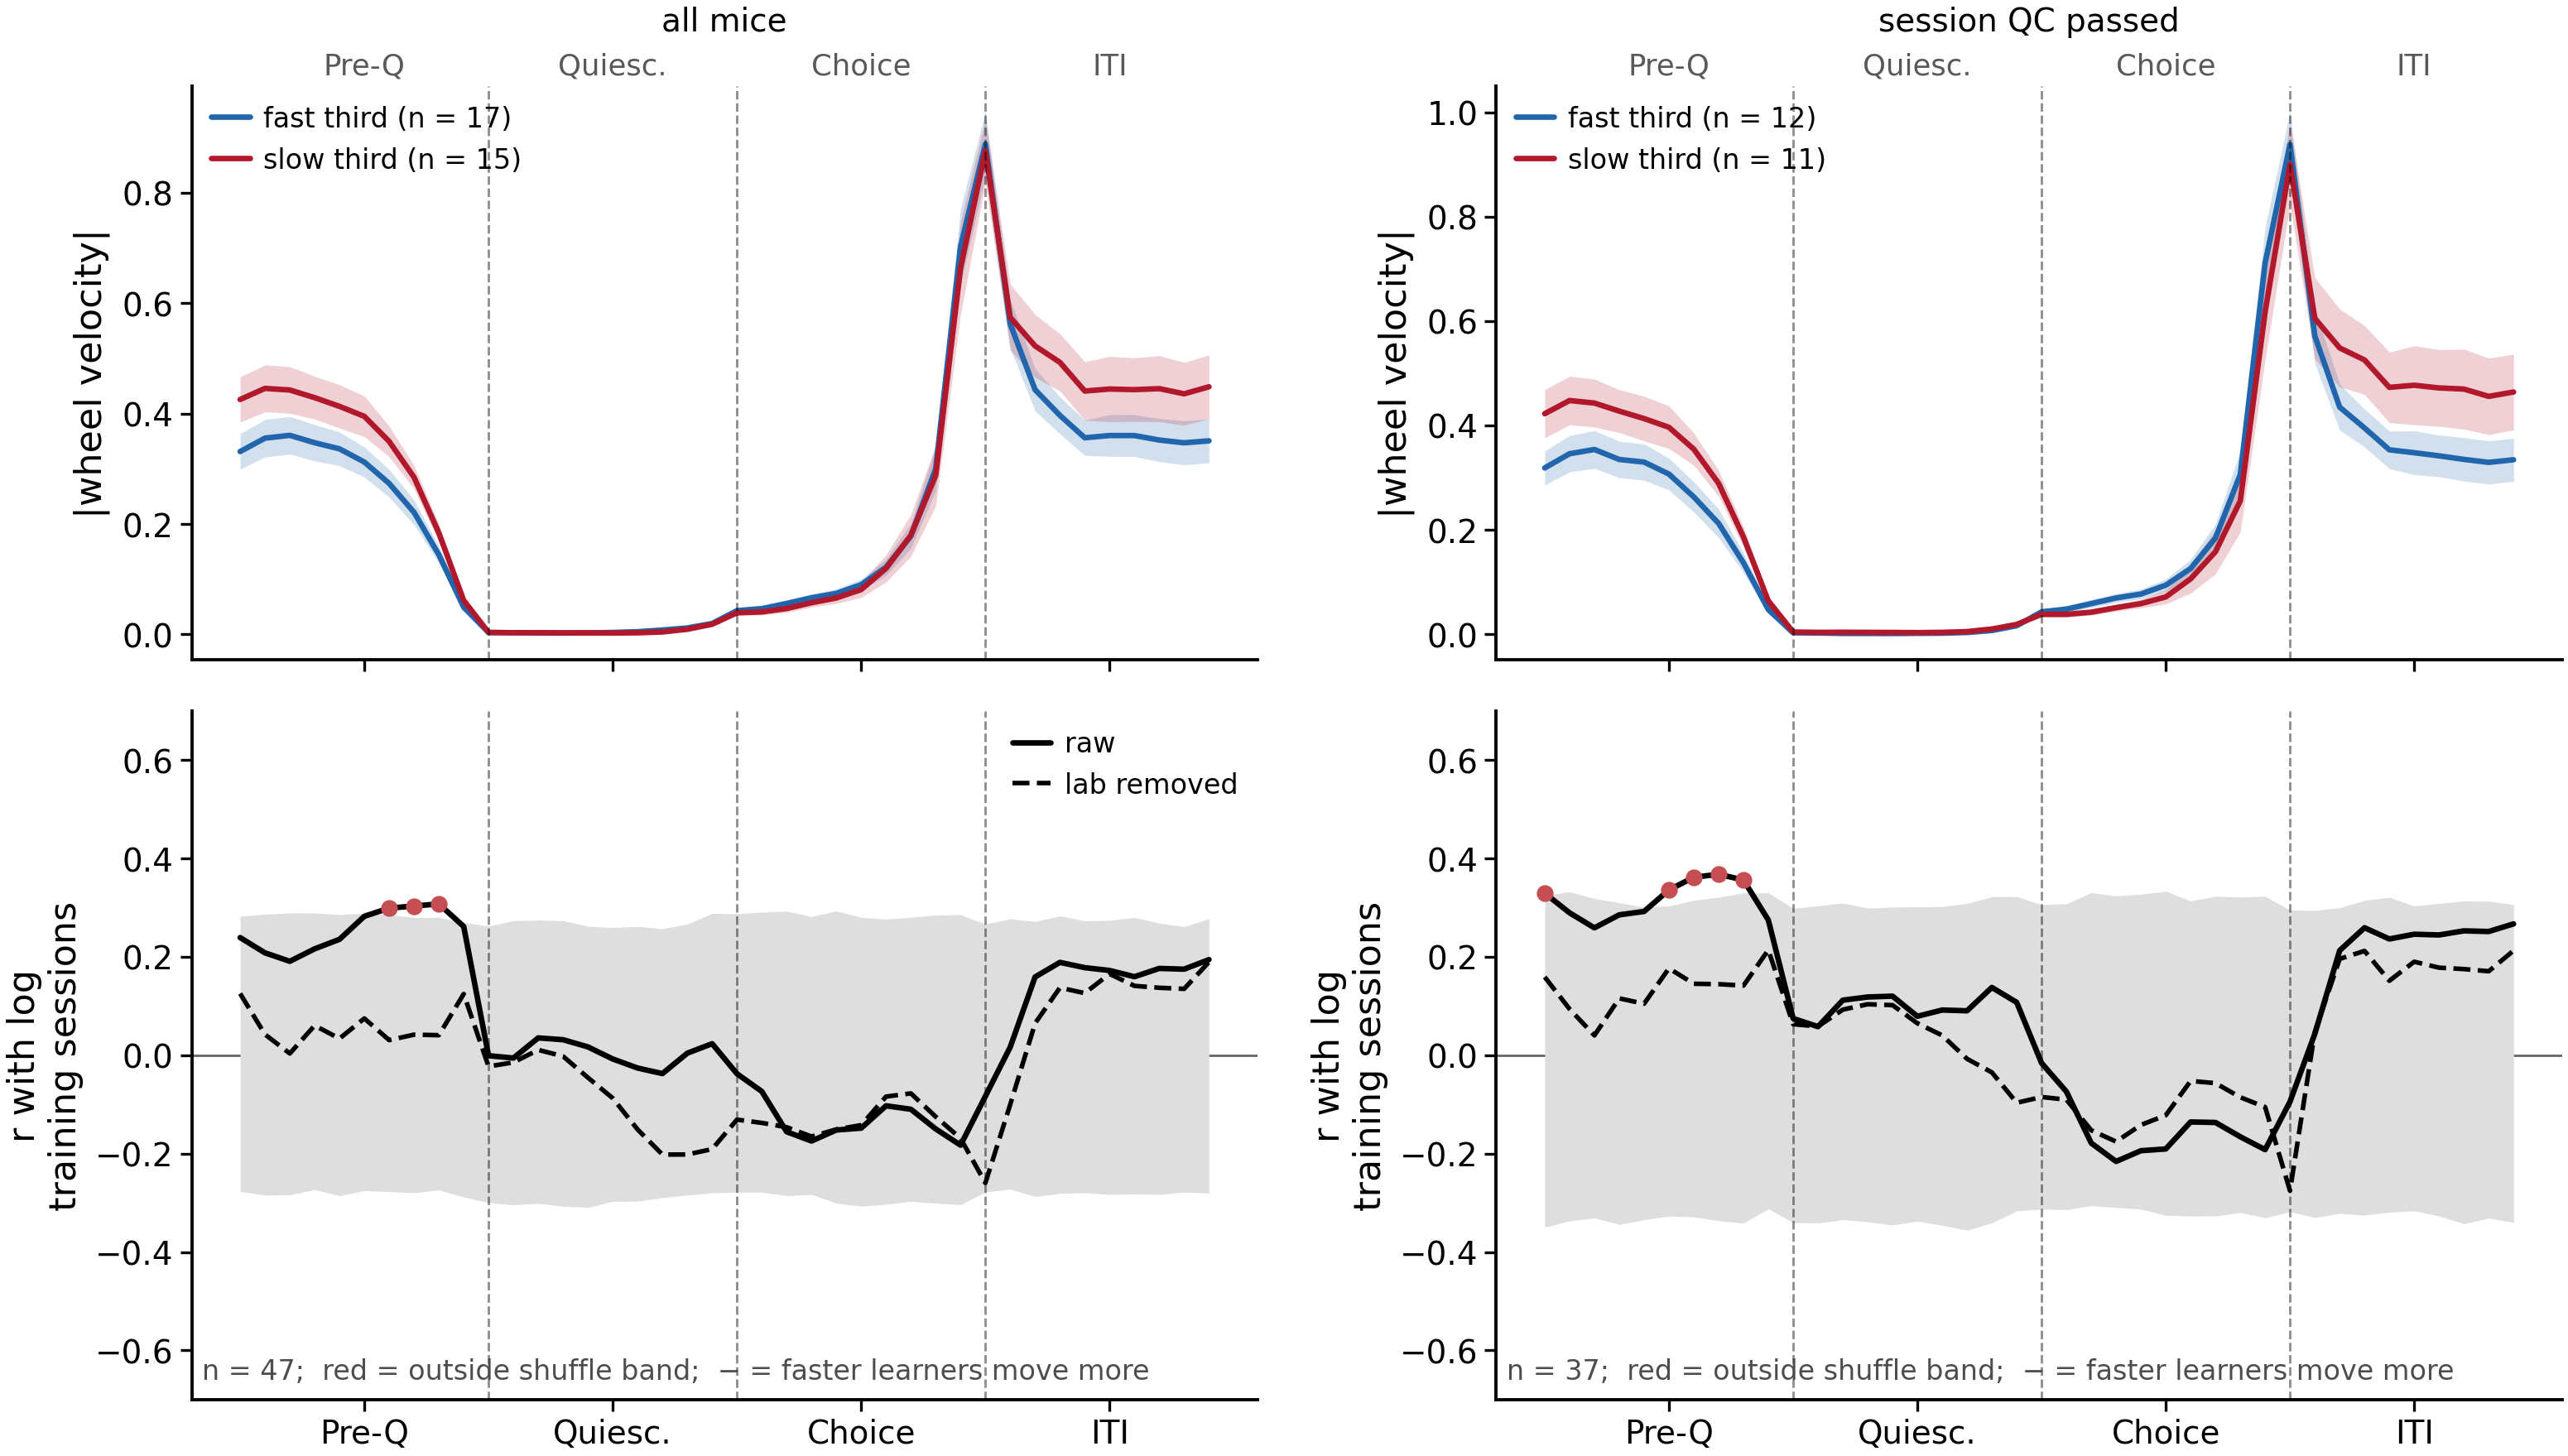

n      r      p  \
cohort            test                                                       
all mice          |v| in Pre-quiescence ~ learning speed  47  0.255  0.083   
                  |v| in Quiescence ~ learning speed      47  0.003  0.983   
                  |v| in Choice ~ learning speed          47 -0.156  0.294   
                  |v| in ITI ~ learning speed             47  0.151  0.310   
session QC passed |v| in Pre-quiescence ~ learning speed  37  0.328  0.047   
                  |v| in Quiescence ~ learning speed      37  0.108  0.524   
                  |v| in Choice ~ learning speed          37 -0.175  0.299   
                  |v| in ITI ~ learning speed             37  0.222  0.186   

                                                            rho  p_spearman  \
cohort            test                                                        
all mice          |v| in Pre-quiescence ~ learning speed  0.292       0.046   
                  |v| in Quiescence ~ learning speed      0.045       0.763   
                  |v| in Choice ~ learning speed         -0.184       0.216   
                  |v| in ITI ~ learning speed             0.144       0.334   
session QC passed |v| in Pre-quiescence ~ learning speed  0.364       0.027   
                  |v| in Quiescence ~ learning speed      0.156       0.357   
                  |v| in Choice ~ learning speed         -0.194       0.251   
                  |v| in ITI ~ learning speed             0.204       0.226   

                                                          r_lab  p_lab  
cohort            test                                                  
all mice          |v| in Pre-quiescence ~ learning speed  0.056  0.747  
                  |v| in Quiescence ~ learning speed     -0.114  0.516  
                  |v| in Choice ~ learning speed         -0.144  0.411  
                  |v| in ITI ~ learning speed             0.091  0.604  
session QC passed |v| in Pre-quiescence ~ learning speed  0.129  0.521  
                  |v| in Quiescence ~ learning speed      0.033  0.869  
                  |v| in Choice ~ learning speed         -0.102  0.614  
                  |v| in ITI ~ learning speed             0.147  0.464

In [18]:
def bin_corr_panel(ax, P, y, color='k', n_perm=1000, seed=0, labs=None, x=None):
    # r(bin) of each column of P (mice x bins) with y; pointwise permutation band; lab-removed curve if labs given
    rng = np.random.default_rng(seed)
    ok = np.isfinite(y) & np.isfinite(P).all(1)
    P, y = P[ok], y[ok]
    r = zcorr(P, y)
    null = np.vstack([zcorr(P, rng.permutation(y)) for _ in range(n_perm)])
    lo, hi = np.percentile(null, [2.5, 97.5], axis=0)
    x = np.arange(P.shape[1]) if x is None else np.asarray(x)
    ax.fill_between(x, lo, hi, color='0.87', lw=0)
    ax.plot(x, r, color=color, lw=1.2, label='raw')
    if labs is not None:
        lb = np.asarray(labs)[ok]; keep = pd.notna(lb)
        D = lc._lab_design(lb[keep])
        rl = zcorr(np.column_stack([resid(c, D) for c in P[keep].T]), resid(y[keep], D))
        ax.plot(x, rl, color=color, lw=1, ls='--', label='lab removed')
    out = (r < lo) | (r > hi)
    ax.scatter(x[out], r[out], s=7, color=WHEEL_C, zorder=3)
    ps.zero_line(ax)
    return r, lo, hi, int(ok.sum())


VP = pd.DataFrame(np.vstack([np.nanmean(V[g], 0) for g in groups]), index=mice)    # mouse x 40 bins

fig, axs = plt.subplots(2, 2, figsize=(8, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.2]))
for col, (name, ms) in enumerate([('all mice', list(VP.index)), ('session QC passed', QC_MICE)]):
    ms = [m for m in ms if np.isfinite(LS.get(m, np.nan))]
    y = LS.reindex(ms).to_numpy(float)
    # top: profiles by learning-speed tercile
    ax = axs[0, col]
    terc = pd.qcut(LS.reindex(ms), 3, labels=['fast', 'middle', 'slow'])
    for lvl, c in [('fast', '#2166AC'), ('slow', '#B2182B')]:
        Pm = VP.loc[terc.index[terc == lvl]].to_numpy()
        m_, s_ = Pm.mean(0), Pm.std(0) / np.sqrt(len(Pm))
        ax.plot(np.arange(NB), m_, color=c, lw=1.2, label=f'{lvl} third (n = {len(Pm)})')
        ax.fill_between(np.arange(NB), m_ - s_, m_ + s_, color=c, alpha=0.2, lw=0)
    ps.epoch_lines(ax, NB, label=True, names=ps.EPOCH_SHORT)
    ax.set_ylabel('|wheel velocity|'); ax.legend(fontsize=6, frameon=False, loc='upper left')
    ax.set_title(name, fontsize=7, pad=12)
    # bottom: r per bin
    ax = axs[1, col]
    r, lo, hi, n = bin_corr_panel(ax, VP.loc[ms].to_numpy(), y, color='k', labs=lc.MOUSE_LAB.reindex(ms).to_numpy())
    ps.epoch_lines(ax, NB)
    ax.set_ylim(-0.7, 0.7); ax.set_ylabel('r with log\ntraining sessions')
    ax.set_xticks([5, 15, 25, 35]); ax.set_xticklabels(ps.EPOCH_SHORT)
    ax.text(0.01, 0.03, f'n = {n};  red = outside shuffle band;  − = faster learners move more',
            transform=ax.transAxes, fontsize=6, color='0.3')
axs[1, 0].legend(fontsize=6, frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

# per-epoch means, the scalar version
ep_rows = []
for name, ms in [('all mice', list(VP.index)), ('session QC passed', QC_MICE)]:
    d = pd.DataFrame({ph: VP.loc[ms].iloc[:, k * 10:(k + 1) * 10].mean(1) for k, ph in enumerate(EP)})
    d['log_train'] = LS; d['lab'] = lc.MOUSE_LAB
    for ph in EP:
        ep_rows.append(dict(cohort=name, **corr_row(d, ph, 'log_train', label=f'|v| in {ph} ~ learning speed')))
pd.DataFrame(ep_rows).set_index(['cohort', 'test'])[['n', 'r', 'p', 'rho', 'p_spearman', 'r_lab', 'p_lab']].round(3)

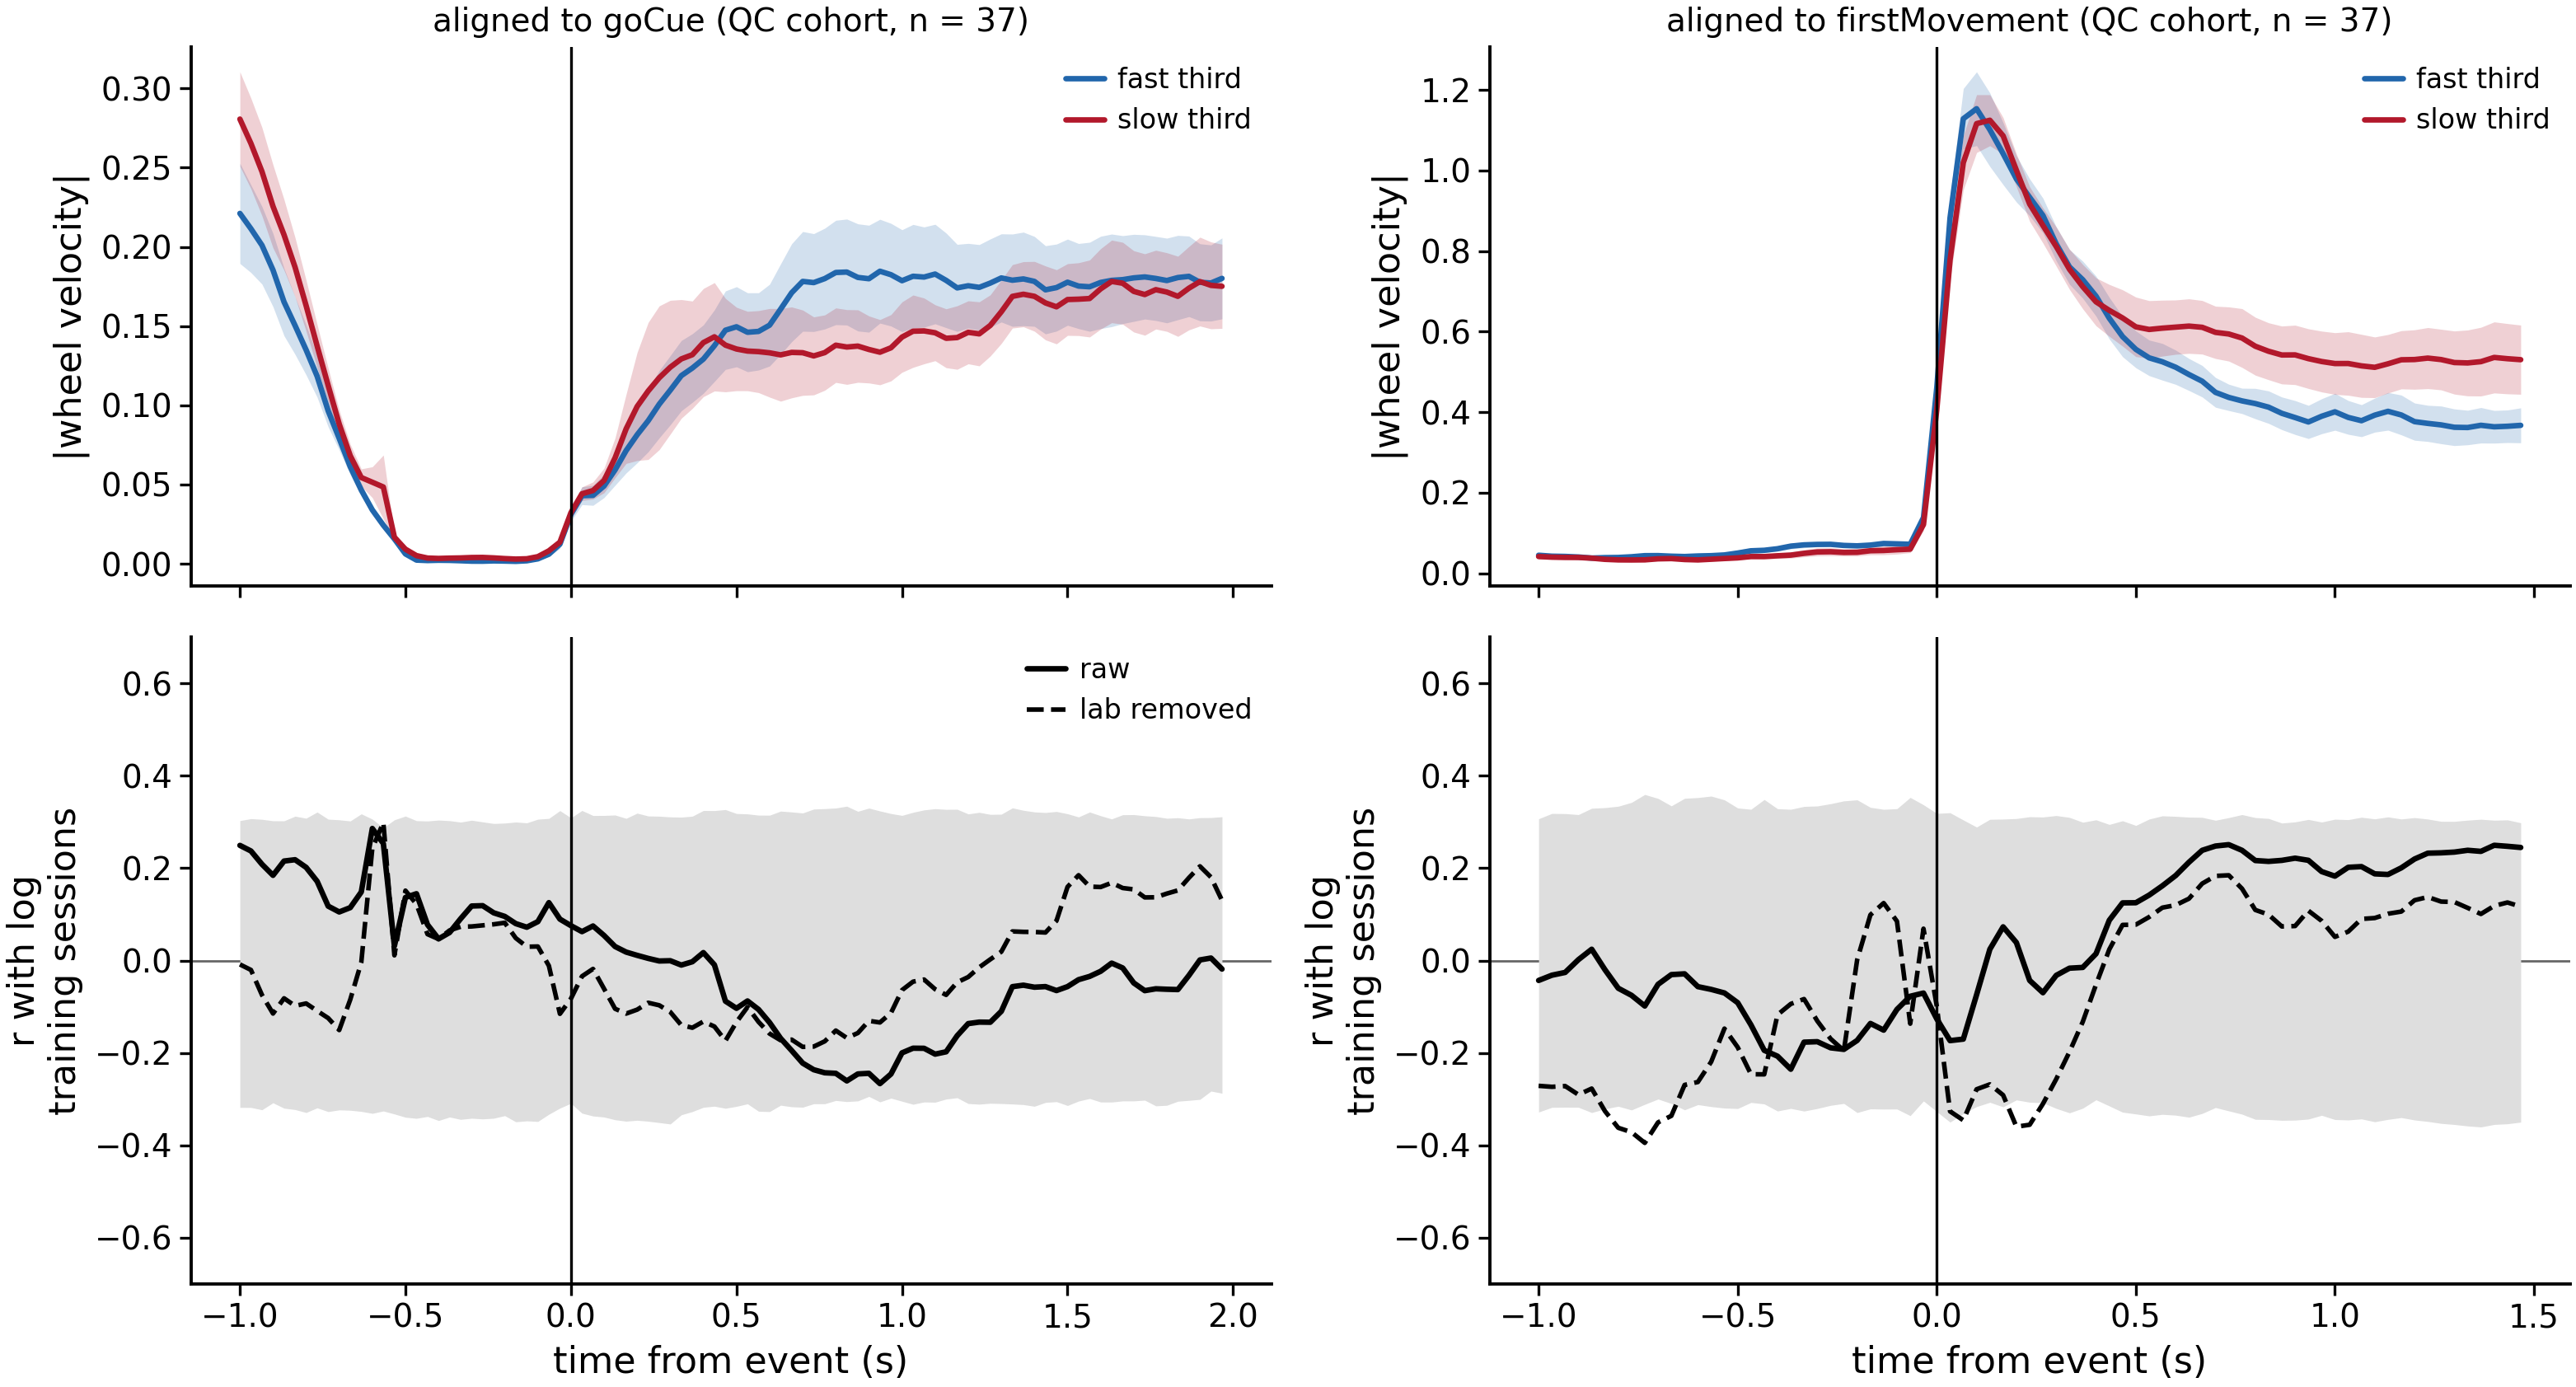

In [19]:
# unwarped: |v| around go cue and around first movement, real time
GRID = {'goCue_times': np.arange(-1.0, 2.0, 1 / 30), 'firstMovement_times': np.arange(-1.0, 1.5, 1 / 30)}


def event_aligned(mouse, session, event, grid):
    tt = wd.session_trials(mouse, session)
    f = wd.os.path.join(wd.DM_DIR, f'design_matrix_{session}_{mouse}')
    dm = pd.read_parquet(f, columns=['Bin', 'avg_wheel_vel']).dropna().sort_values('Bin')
    b, v = dm['Bin'].to_numpy(float), np.abs(dm['avg_wheel_vel'].to_numpy(float))
    ev = tt[event].to_numpy(float); ev = ev[np.isfinite(ev)]
    M = np.vstack([np.interp(e + grid, b, v, left=np.nan, right=np.nan) for e in ev])
    return np.nanmean(M, 0)


EV = {}
for event, grid in GRID.items():
    EV[event] = pd.DataFrame({m: event_aligned(m, mouse_session[m], event, grid) for m in mice}).T

fig, axs = plt.subplots(2, 2, figsize=(8, 4.4), sharex='col', gridspec_kw=dict(height_ratios=[1, 1.2]))
ms = [m for m in QC_MICE if np.isfinite(LS.get(m, np.nan))]
y = LS.reindex(ms).to_numpy(float)
terc = pd.qcut(LS.reindex(ms), 3, labels=['fast', 'middle', 'slow'])
for col, (event, grid) in enumerate(GRID.items()):
    P = EV[event].loc[ms].to_numpy()
    ax = axs[0, col]
    for lvl, c in [('fast', '#2166AC'), ('slow', '#B2182B')]:
        Pm = P[(terc == lvl).to_numpy()]
        m_, s_ = Pm.mean(0), Pm.std(0) / np.sqrt(len(Pm))
        ax.plot(grid, m_, color=c, lw=1.2, label=f'{lvl} third'); ax.fill_between(grid, m_ - s_, m_ + s_, color=c, alpha=0.2, lw=0)
    ax.axvline(0, color='k', lw=0.6); ax.set_ylabel('|wheel velocity|')
    ax.set_title(f'aligned to {event.replace("_times", "")} (QC cohort, n = {len(ms)})', fontsize=7)
    ax.legend(fontsize=6, frameon=False)
    ax = axs[1, col]
    r, lo, hi, n = bin_corr_panel(ax, P, y, labs=lc.MOUSE_LAB.reindex(ms).to_numpy(), x=grid)
    ax.axvline(0, color='k', lw=0.6); ax.set_ylim(-0.7, 0.7)
    ax.set_xlabel('time from event (s)'); ax.set_ylabel('r with log\ntraining sessions')
axs[1, 0].legend(fontsize=6, frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

### Distribution of wheel speeds per epoch, by learning-speed quartile

Raw, unwarped samples from the design matrix (~30 Hz), each assigned to its epoch with the same
boundaries as above. QC cohort, split into quartiles of log(training sessions); Q1 learns fastest.

* **Top row:** the distribution of log10 |wheel velocity|. Each mouse's density is computed first,
  then averaged within its quartile, so every mouse counts once however long its session was.
  Samples below 10⁻³ rad/s are piled into the leftmost bin.
* **Bottom rows:** the two pre-registered wheel-vigor constructs from `wheel_vigor.py`, per mouse
  and epoch: the **fraction of time moving** (|v| > 0.1) and the **median speed while moving**.
  ρ is Spearman against log(training sessions) as a continuous variable, not the quartiles.

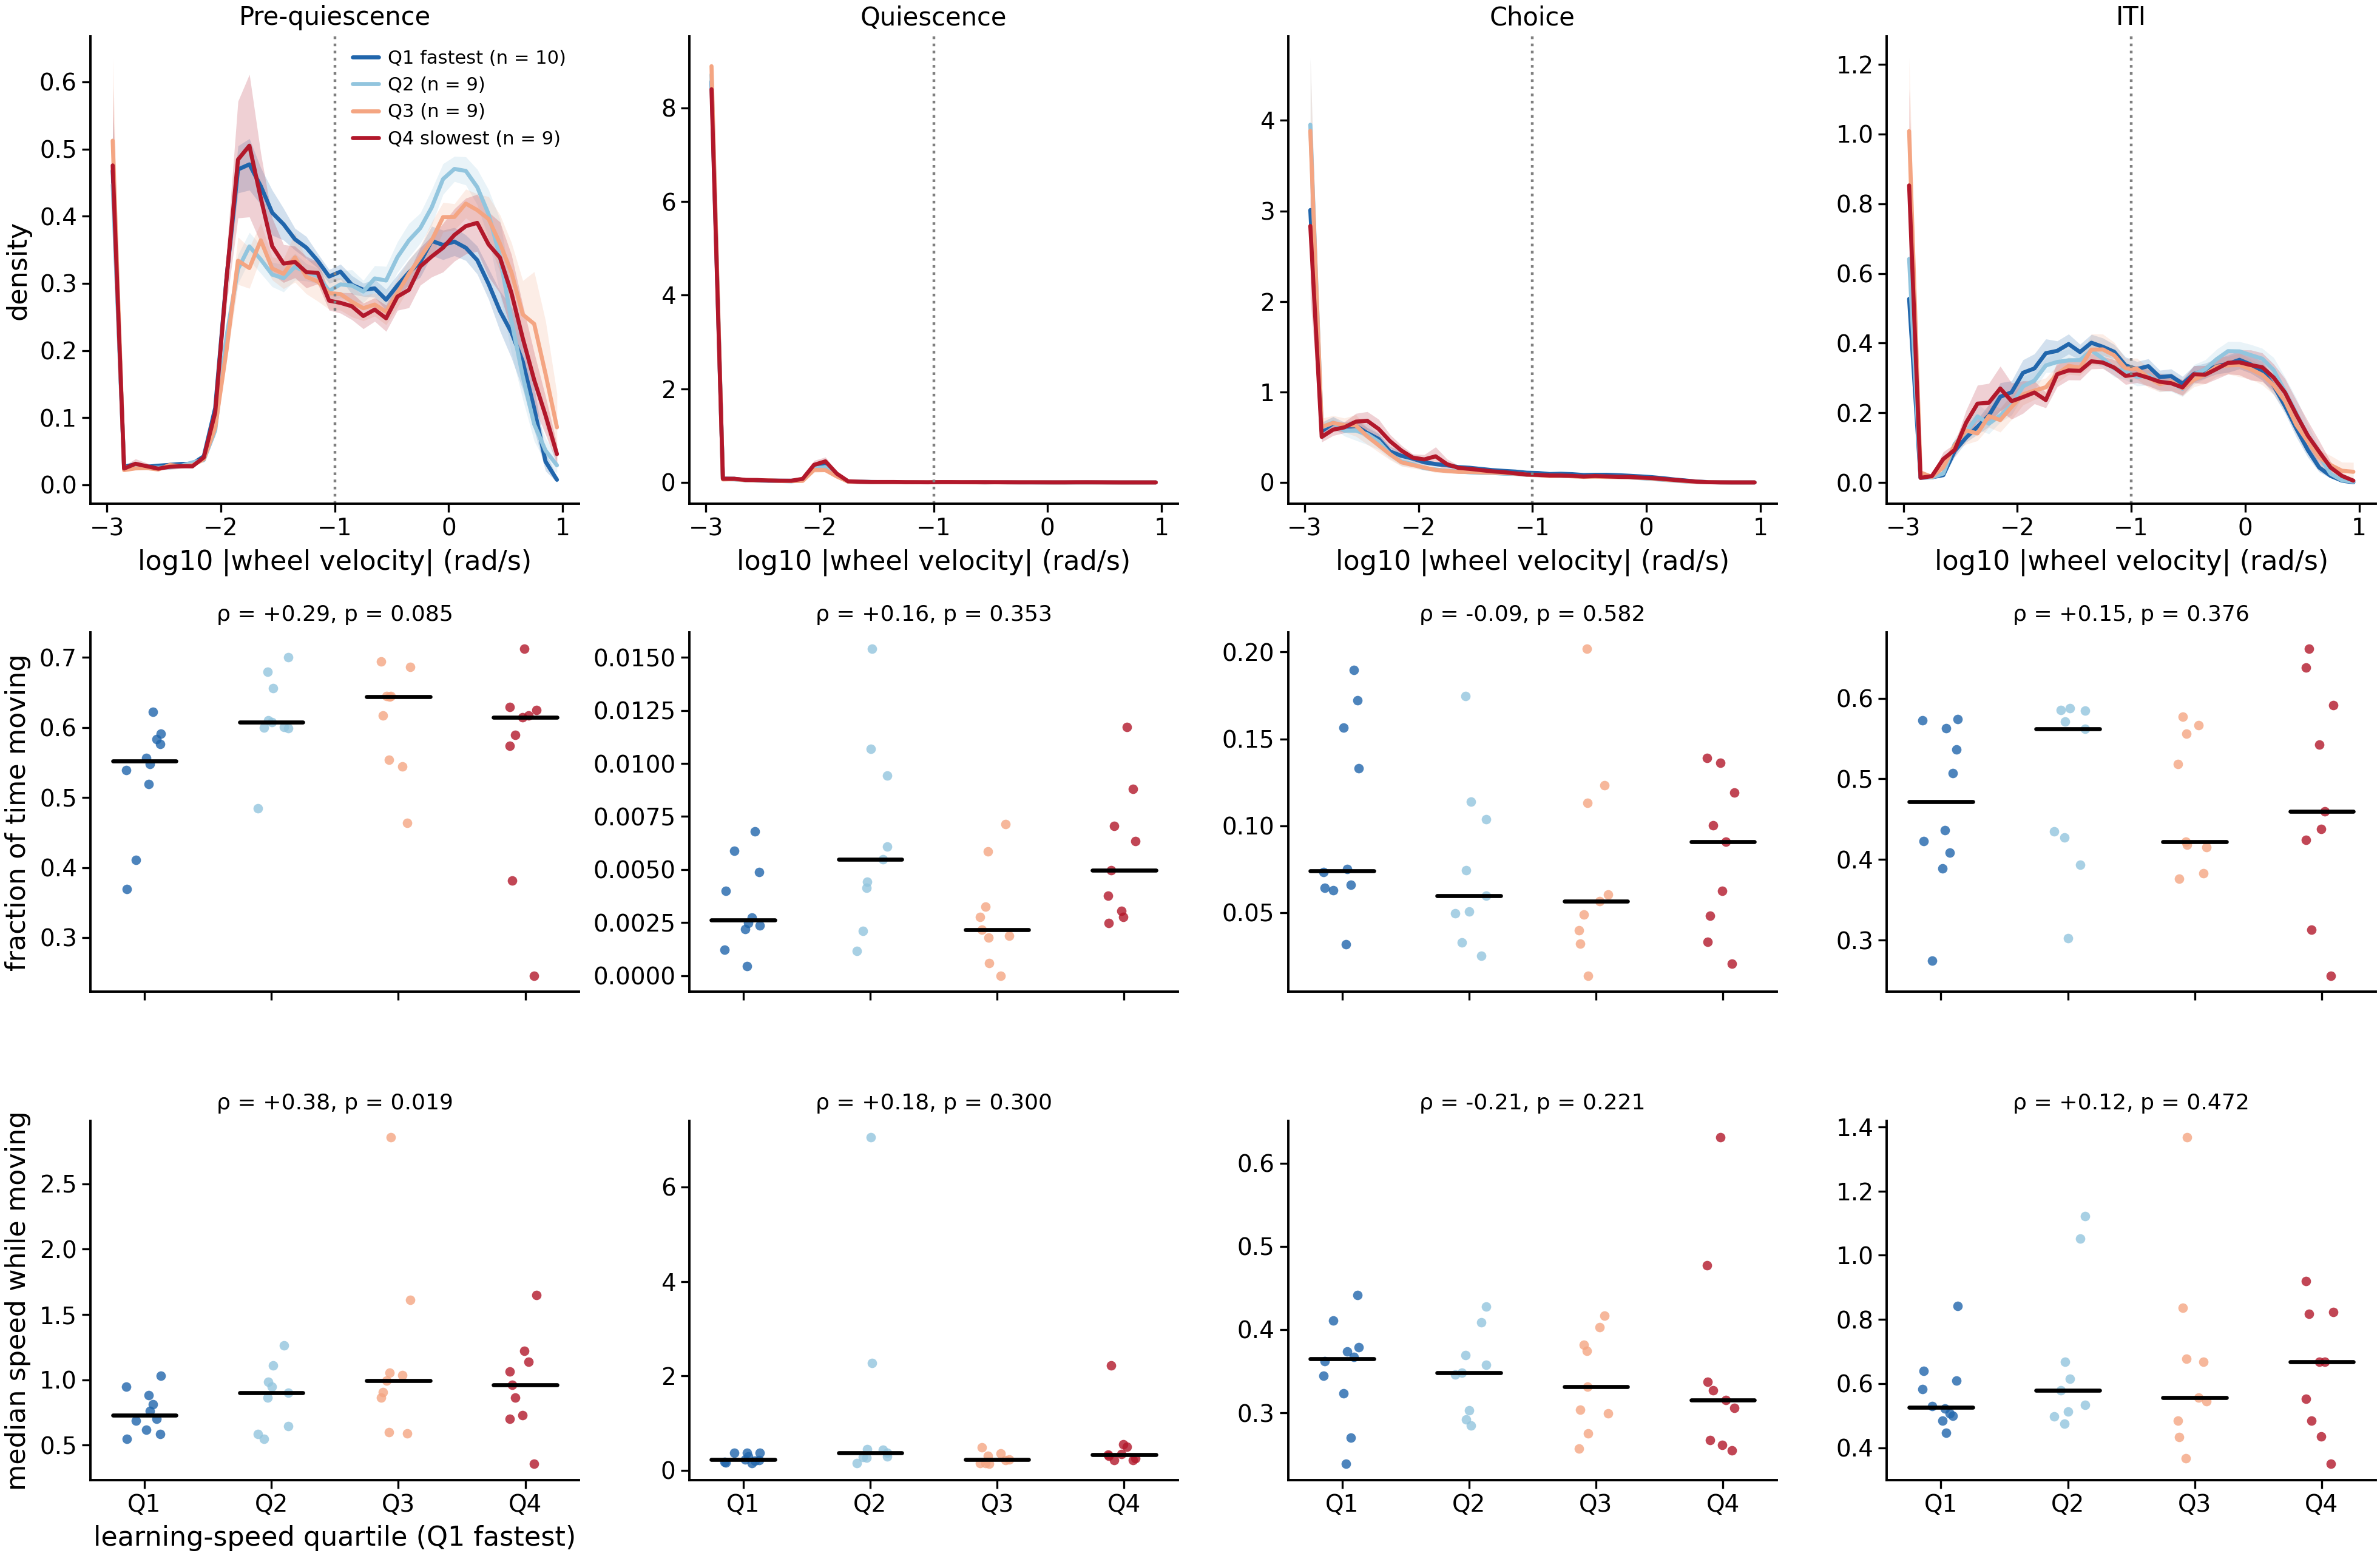

median of per-mouse values by quartile:


frac_moving                          median_moving         \
quartile        Q1 fastest     Q2     Q3 Q4 slowest    Q1 fastest     Q2   
epoch                                                                      
Pre-quiescence       0.552  0.607  0.644      0.615         0.730  0.900   
Quiescence           0.003  0.005  0.002      0.005         0.223  0.366   
Choice               0.074  0.060  0.057      0.091         0.365  0.348   
ITI                  0.472  0.562  0.422      0.460         0.526  0.579   

                                  
quartile           Q3 Q4 slowest  
epoch                             
Pre-quiescence  0.992      0.959  
Quiescence      0.224      0.336  
Choice          0.332      0.315  
ITI             0.556      0.667

In [20]:
MOVE_THRESH = 0.1
EDGES = np.linspace(-3, 1, 41)
CENT = (EDGES[:-1] + EDGES[1:]) / 2


def epoch_samples(mouse, session):
    # |v| samples per epoch for one session (raw time), using wd.phase_bounds
    tt = wd.session_trials(mouse, session)
    dm = pd.read_parquet(wd.os.path.join(wd.DM_DIR, f'design_matrix_{session}_{mouse}'),
                         columns=['Bin', 'avg_wheel_vel']).dropna().sort_values('Bin')
    b, v = dm['Bin'].to_numpy(float), np.abs(dm['avg_wheel_vel'].to_numpy(float))
    bounds = wd.phase_bounds(tt)
    out = {}
    for k, ph in enumerate(EP):
        lo, hi = bounds[:, k, 0], bounds[:, k, 1]
        ok = np.isfinite(lo) & np.isfinite(hi) & (hi > lo)
        i, j = np.searchsorted(b, lo[ok], 'right'), np.searchsorted(b, hi[ok], 'right')
        out[ph] = np.concatenate([v[a:z] for a, z in zip(i, j)]) if ok.any() else np.array([])
    return out


qmice = [m for m in QC_MICE if np.isfinite(LS.get(m, np.nan))]
SAMP = {m: epoch_samples(m, mouse_session[m]) for m in qmice}
quart = pd.qcut(LS.reindex(qmice).rank(method='first'), 4, labels=['Q1 fastest', 'Q2', 'Q3', 'Q4 slowest'])
Q_COL = dict(zip(quart.cat.categories, ['#2166AC', '#92C5DE', '#F4A582', '#B2182B']))

dens, summ = {}, []
for m in qmice:
    for ph in EP:
        x = SAMP[m][ph]
        h, _ = np.histogram(np.log10(np.clip(x, 10 ** EDGES[0] + 1e-12, None)), EDGES)
        dens[(m, ph)] = h / max(h.sum(), 1) / np.diff(EDGES)
        mv = x[x > MOVE_THRESH]
        summ.append(dict(mouse_name=m, epoch=ph, frac_moving=np.mean(x > MOVE_THRESH),
                         median_moving=np.median(mv) if len(mv) else np.nan, n_samples=len(x)))
summ = pd.DataFrame(summ)
summ['quartile'] = summ['mouse_name'].map(quart)
summ['log_train'] = summ['mouse_name'].map(LS)

fig, axs = plt.subplots(3, 4, figsize=(10, 6.6), gridspec_kw=dict(height_ratios=[1.3, 1, 1]))
for j, ph in enumerate(EP):
    ax = axs[0, j]
    for q, c in Q_COL.items():
        D = np.vstack([dens[(m, ph)] for m in quart.index[quart == q]])
        mu, se = D.mean(0), D.std(0) / np.sqrt(len(D))
        ax.plot(CENT, mu, color=c, lw=1.2, label=f'{q} (n = {len(D)})')
        ax.fill_between(CENT, mu - se, mu + se, color=c, alpha=0.2, lw=0)
    ax.axvline(np.log10(MOVE_THRESH), color='0.5', ls=':', lw=0.8)
    ax.set_title(ph, fontsize=7.5); ax.set_xlabel('log10 |wheel velocity| (rad/s)')
    if j == 0:
        ax.set_ylabel('density'); ax.legend(fontsize=5.5, frameon=False, loc='upper right')
    for i, (col, lbl) in enumerate([('frac_moving', 'fraction of time moving'),
                                     ('median_moving', 'median speed while moving')], start=1):
        ax = axs[i, j]
        d = summ[summ.epoch == ph]
        for k, q in enumerate(Q_COL):
            y = d.loc[d.quartile == q, col].dropna()
            ax.scatter(k + np.random.default_rng(k).uniform(-0.15, 0.15, len(y)), y, s=8, color=Q_COL[q], alpha=0.8, lw=0)
            ax.plot([k - 0.25, k + 0.25], [y.median()] * 2, color='k', lw=1.2)
        dd = d[[col, 'log_train']].dropna()
        rho, p = spearmanr(dd[col], dd['log_train'])
        ax.set_title(f'ρ = {rho:+.2f}, p = {p:.3f}', fontsize=6.5)
        ax.set_xticks(range(4)); ax.set_xticklabels(['Q1', 'Q2', 'Q3', 'Q4'] if i == 2 else [])
        if j == 0:
            ax.set_ylabel(lbl)
axs[2, 0].set_xlabel('learning-speed quartile (Q1 fastest)')
plt.tight_layout(); plt.show()

print('median of per-mouse values by quartile:')
summ.groupby(['epoch', 'quartile'], observed=True)[['frac_moving', 'median_moving']].median().unstack('quartile').reindex(EP).round(3)

## 8. Summary (numbers from the run saved in this notebook)

**Whisking and wheel movement co-occur moment to moment.** Within a session, at a fixed warped bin,
the wheel moves faster on trials where the mouse is whisking: |v| is 0.36 when whisking and 0.09
when not (41/47 mice higher). The within-session ρ is about 0.5 in pre-quiescence and choice, and
about 0.15 in quiescence, where the wheel barely moves.

**But they are not the same individual trait.** Across mice, session-1 whisking is unrelated to the
fraction of time a mouse moves the wheel (r ≈ −0.1). It is *negatively* related to speed when moving
(r ≈ −0.30). Whisking is not the wheel in disguise, and controlling for wheel barely changes the
results below.

| test | r (p) | lab removed |
|---|---|---|
| proficient whisking ~ LD1 (positive control) | **+0.85** | +0.86 |
| session-1 whisking ~ LD1 | +0.26 (0.09) | +0.11 (0.54) |
| session-1 ~ proficient whisking | +0.28 (0.06), ρ +0.30 (0.04) | +0.16 (0.36) |
| last-training whisking ~ LD1 | **+0.40 (0.003)** | **+0.34 (0.03)** |
| session-1 ~ last-training whisking | +0.36 (0.01) | +0.38 (0.03) |
| LD1 ~ learning speed (reference) | −0.34 (0.01) | −0.38 (0.01) |
| session-1 whisking ~ learning speed | −0.14 (0.33) | −0.21 (0.23) |
| last-training whisking ~ learning speed | −0.17 (0.21) | −0.16 (0.32) |
| proficient whisking ~ learning speed | −0.24 (0.11) | **−0.38 (0.02)** |

* **LD1 at proficiency is largely whisking** (r = 0.85).
* **Session-1 whisking points the right way but is not significant.** It is weaker than this sample
  can detect (|r| ≈ 0.41 at 80% power), and most of the raw trend is **lab**. Whisking is a
  motion-energy measure, so camera and rig differences between labs are a plausible contributor.
* **By the last training session, whisking already tracks LD1, and this survives lab removal.**
  Mice that whisk more in session 1 also whisk more at the end of training (also lab-robust).
* **Learning speed:** every whisking measure has the predicted sign (more whisking → fewer
  sessions), but only proficient whisking reaches significance, and only after lab removal.
  Session-1 whisking adds nothing beyond LD1.
* Nothing in the exploratory family survives BH correction.

**Syllables per epoch vs learning speed (section 7).** One cell stands out: the fastest wheel
state, **paw-wheel 6** (|v| ≈ 1.5, 3% of bins), during the **choice** epoch. Mice that use it more
in session 1 learn faster: r = −0.44 across all 47 mice and −0.52 in the 37-mouse QC cohort, where
it survives BH over the 40 cells (q = 0.04). It holds after removing lab (r = −0.51, p = 0.007),
though not after BH there. The bin-by-bin view puts the effect across the whole movement period.
The other fast state, **PW 7**, leans the other way (+0.29 to +0.34), so this is not simply "more
vigorous wheel turning". Whisking in the choice epoch is negative (r ≈ −0.3) but inside the null.
Treat the PW 6 result as a lead: it is one exploratory cell out of 40, and the legacy states have no
paw-side labels here to say what separates PW 6 from PW 7.

**Wheel velocity per bin vs learning speed (section 7b).** The choice-period movement itself is
the same in fast and slow learners: peak speed and timing overlap whether warped or aligned to the
go cue or first movement. The differences are *outside* the response. Slow learners move the wheel
more in **pre-quiescence** (QC cohort: r = +0.35, p = 0.04; ρ = +0.40) and keep turning it after the
response and into the ITI (n.s.). Both shrink once lab is removed (pre-quiescence r = +0.17). Read
this as "slow learners fidget more between trials", which is the opposite of an engagement boost
from overall wheel activity. It is consistent with the PW 6 result being about *how* the choice
movement is made rather than how much the mouse moves.

**Speed distributions by learning-speed quartile.** The distributions overlap heavily in every
epoch. The one systematic shift is in **pre-quiescence**: the fastest quartile has more slow,
low-amplitude movement (log10 |v| ≈ −2 to −1) and less fast turning (|v| ≈ 1), so its median speed
while moving is lower (ρ = +0.37 with log sessions, p = 0.03), and it moves a slightly smaller
fraction of the time (ρ = +0.30, p = 0.07). The choice epoch is mostly stillness in session 1
(about 7% of samples above threshold, because reaction times are long), and it does not separate
the quartiles.

**What would make this decisive:** the limit is one early session per mouse, not the number of
mice. Whisk states for sessions 2–3 (on the analysis machine) would let several early sessions be
averaged. That is what moved the early→proficient correlation for wheel vigor.